
# NewX Services – Inventory Management & Spare Parts Forecasting



**Domain:** Inventory Management and Predictive Analytics

## 1. Introduction

Inventory management plays an important role in vehicle service operations. Service centres need to maintain adequate spare parts and service items to meet customer requirements while avoiding unnecessary inventory costs.

Historical invoice and vehicle service records can help identify frequently used service items, recurring demand patterns, and changes in service activity over time.

This project focuses on analysing historical service and invoice data from NewX Services to identify useful patterns and explore a data-driven approach to inventory demand forecasting.

## 1.1  Business Objective

The primary objective is to analyse historical vehicle service and invoice records to understand service-item demand patterns and support inventory planning.

The analysis aims to help service centres improve item availability, reduce unnecessary stock, and support Just-in-Time (JIT) inventory management.

## 1.2  Problem Statement

Inadequate inventory planning may lead to spare-part shortages, service delays, or excess stock. Analysing historical service records can provide insights into which items are frequently recorded and how service activity changes over time.

The project will investigate whether the available dataset supports a meaningful demand forecasting approach.

## 1.3  Project Scope

The project includes:

* Connecting to the provided database.
* Retrieving and understanding the available data.
* Cleaning missing values and correcting data types.
* Exploring service-item and vehicle-related patterns.
* Analysing invoice activity over time.
* Developing suitable analytical features.
* Evaluating an appropriate forecasting approach, subject to the available target data.
* Presenting findings and business recommendations.

## 1.4  Tools and Technologies

* Python
* Jupyter Notebook
* Pandas and NumPy
* Matplotlib and Seaborn
* SQL and SQLAlchemy
* Scikit-learn, if a suitable machine learning task is supported by the data


## 2. Dataset Description

The dataset is retrieved from the NewX Services project database. It contains historical invoice and vehicle service information.

The available dataset contains the following fields:

| Column                  | Description                                               |
| ----------------------- | --------------------------------------------------------- |
| `invoice_date`          | Date of the invoice                                       |
| `job_card_date`         | Date associated with the vehicle service job card         |
| `business_partner_name` | Business partner or customer identifier                   |
| `vehicle_no`            | Vehicle registration identifier                           |
| `vehicle_model`         | Vehicle model                                             |
| `current_km_reading`    | Vehicle kilometre reading                                 |
| `invoice_line_text`     | Description of an item or service recorded on the invoice |

The dataset will be examined to determine its completeness, data types, duplicate records, and suitability for demand analysis.

**Data limitation:** The available fields do not include an explicit item quantity column. Therefore, invoice-line frequency may be investigated as a proxy for recorded item demand, but it must not be interpreted as actual quantity sold or consumed.


## 3. Importing Required Libraries

The required Python libraries are imported for database connectivity, data manipulation, statistical analysis, and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
import getpass

print("Libraries imported successfully!")

Libraries imported successfully!


## 4. Database Connection

The project database is accessed using SQLAlchemy and the PyMySQL driver. Database credentials are entered securely instead of being written directly in the notebook.

In [2]:

# Section 4: Database Connection

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
import getpass

db_host = "18.136.157.135"
db_port = 3306
db_name = "project_service_data"
db_user = "dm_usdata_sql"

db_password = getpass.getpass("Enter your MySQL password: ")

connection_url = URL.create(
    drivername="mysql+pymysql",
    username=db_user,
    password=db_password,
    host=db_host,
    port=db_port,
    database=db_name
)

engine = create_engine(
    connection_url,
    pool_pre_ping=True
)

connection = None

try:
    connection = engine.connect()

    result = connection.execute(text("SELECT 1"))

    print("Database connection successful!")
    print("Connection test result:", result.scalar())

except Exception as e:
    if connection is not None:
        connection.close()

    connection = None

    print("Database connection failed.")
    print(type(e).__name__, str(e))

Enter your MySQL password:  ········


Database connection successful!
Connection test result: 1


### 4.1 Inspect Available Database Tables

In [3]:
if connection is None or connection.closed:
    raise RuntimeError(
        "Database connection is not open. Run Section 4 successfully first."
    )

tables = pd.read_sql(
    text("SHOW TABLES"),
    connection
)

print("Available database tables:")
display(tables)

Available database tables:


,Tables_in_project_service_data
0,service_data


## 5.  Data Loading

### 5.1   Loading Sample Records

A sample of 10 records is retrieved from the `service_data` table to inspect the dataset structure, column names, and sample values before performing detailed data analysis.


In [4]:
query = "SELECT * FROM service_data LIMIT 10"

with engine.connect() as connection:
    df = pd.read_sql(query, connection)

print("Data loaded successfully!")
print("Shape:", df.shape)

df.head()

Data loaded successfully!
Shape: (10, 7)


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
0,30-05-17,30-05-17,shivXXXXXXXXXX,KA03MFXXXX,BAJAJ AVENGER STREET 220,50000,ENGINE OIL
1,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,ENGINE OIL
2,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,POLISH
3,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,CONSUMABLES
4,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,COOLANT OIL


### 5.2 Loading the Dataset

The historical service records are retrieved from the `service_data` table in the project database. The complete dataset is stored in a Pandas DataFrame for further analysis.

In [5]:
# Load the complete dataset
query = "SELECT * FROM service_data"

with engine.connect() as connection:
    df = pd.read_sql(query, connection)

print("Complete dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Complete dataset loaded successfully!
Number of rows: 28482
Number of columns: 7


## 6. Data Understanding

Initial data exploration is performed to understand the dataset structure, column names, data types, missing values, duplicate records, and sample observations.

In [6]:
# 1. Display column names
print("Column Names:")
print(df.columns.tolist())

# 2. Check data types and dataset information
print("\nDataset Information:")
df.info()

# 3. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 5. Display first five records
print("\nFirst Five Records:")
display(df.head())

Column Names:
['invoice_date', 'job_card_date', 'business_partner_name', 'vehicle_no', 'vehicle_model', 'current_km_reading', 'invoice_line_text']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28482 entries, 0 to 28481
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   invoice_date           28482 non-null  object
 1   job_card_date          28482 non-null  object
 2   business_partner_name  28482 non-null  object
 3   vehicle_no             28482 non-null  object
 4   vehicle_model          28482 non-null  object
 5   current_km_reading     28482 non-null  object
 6   invoice_line_text      28476 non-null  object
dtypes: object(7)
memory usage: 1.5+ MB

Missing Values:
invoice_date             0
job_card_date            0
business_partner_name    0
vehicle_no               0
vehicle_model            0
current_km_reading       0
invoice_line_text        6
dtype: int64

Dupl

,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
0,30-05-17,30-05-17,shivXXXXXXXXXX,KA03MFXXXX,BAJAJ AVENGER STREET 220,50000,ENGINE OIL
1,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,ENGINE OIL
2,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,POLISH
3,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,CONSUMABLES
4,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,COOLANT OIL


## 7. Data Cleaning and Preprocessing

Data cleaning is performed to improve data consistency and prepare the dataset for analysis. The process includes preserving the original data, converting dates and numeric fields, standardizing item descriptions, checking missing values, and investigating duplicate records before deciding how to handle them.


In [7]:
df_original = df.copy()

print("Original dataset shape:", df_original.shape)

Original dataset shape: (28482, 7)


### 7.1 Data Type Conversion

The date columns are converted to datetime format, and vehicle kilometre readings are converted to a numeric format to support further analysis.

In [8]:
df['invoice_date'] = pd.to_datetime(
    df['invoice_date'],
    format='%d-%m-%y',
    errors='coerce'
)

df['job_card_date'] = pd.to_datetime(
    df['job_card_date'],
    format='%d-%m-%y',
    errors='coerce'
)

df['current_km_reading'] = pd.to_numeric(
    df['current_km_reading'],
    errors='coerce'
)

print("Data types after conversion:")
print(df.dtypes)

print("\nMissing values after conversion:")
print(
    df[
        ['invoice_date', 'job_card_date', 'current_km_reading']
    ].isnull().sum()
)

Data types after conversion:
invoice_date             datetime64[ns]
job_card_date            datetime64[ns]
business_partner_name            object
vehicle_no                       object
vehicle_model                    object
current_km_reading                int64
invoice_line_text                object
dtype: object

Missing values after conversion:
invoice_date          0
job_card_date         0
current_km_reading    0
dtype: int64


### 7.2 Handling Missing Values

The dataset was examined for missing values. Six records contain missing values in the `invoice_line_text` column. These missing descriptions are labelled as `UNKNOWN` to preserve the records without assuming the missing item names.


In [9]:
# Standardize invoice item descriptions
df['invoice_line_text'] = (
    df['invoice_line_text']
    .str.strip()
    .str.upper()
)

# Handle missing item descriptions
df['invoice_line_text'] = (
    df['invoice_line_text']
    .fillna('UNKNOWN')
)

# Verify missing values
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
invoice_date             0
job_card_date            0
business_partner_name    0
vehicle_no               0
vehicle_model            0
current_km_reading       0
invoice_line_text        0
dtype: int64


### 7.3 Duplicate Records Analysis

Duplicate records are identified to understand repeated entries in the dataset. Since identical records may represent either duplicate data entry or repeated service transactions, they are examined before deciding whether to remove them. The original dataset is preserved for comparison.



In [10]:
# Compare the original dataset with the cleaned dataset

print("Original dataset shape:", df_original.shape)
print("Current dataset shape:", df.shape)

print("\nExact duplicate rows:", df.duplicated().sum())

# Check how many times each complete record appears
record_counts = (
    df.groupby(df.columns.tolist(), dropna=False)
    .size()
    .reset_index(name="record_count")
)

repeated_records = record_counts[
    record_counts["record_count"] > 1
].sort_values("record_count", ascending=False)

print("\nNumber of unique records that are repeated:",
      len(repeated_records))

print("\nHighest repetition count:",
      repeated_records["record_count"].max())

display(repeated_records.head(10))

Original dataset shape: (28482, 7)
Current dataset shape: (28482, 7)

Exact duplicate rows: 383

Number of unique records that are repeated: 337

Highest repetition count: 13


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text,record_count
10707,2018-02-27,2018-02-27,PRAVXXXXXXXXXX,KA04JBXXXX,BAJAJ PULSAR 150,24447,,13
17151,2018-07-10,2018-07-10,santXXXXXXXXXX,KA53ETXXXX,BAJAJ PULSAR 150,5620,CHAIN LUBRICATION,5
17152,2018-07-10,2018-07-10,santXXXXXXXXXX,KA53ETXXXX,BAJAJ PULSAR 150,5620,CONSUMABLES,5
17153,2018-07-10,2018-07-10,santXXXXXXXXXX,KA53ETXXXX,BAJAJ PULSAR 150,5620,ENGINE OIL,5
17154,2018-07-10,2018-07-10,santXXXXXXXXXX,KA53ETXXXX,BAJAJ PULSAR 150,5620,POLISH,5
17149,2018-07-10,2018-07-10,santXXXXXXXXXX,KA53ETXXXX,BAJAJ PULSAR 150,5620,3M OIL,5
17150,2018-07-10,2018-07-10,santXXXXXXXXXX,KA53ETXXXX,BAJAJ PULSAR 150,5620,AIR FILTER,5
10713,2018-02-27,2018-02-27,RAMEXXXXXXXXXX,KA53Y5XXXX,BAJAJ DISCOVER,23784,BRAKE SHOE,4
10790,2018-03-01,2018-03-01,DARSXXXXXXXXXX,KA04JAXXXX,BAJAJ PULSAR 150,36075,,4
25281,2018-11-27,2018-11-27,vinaXXXXXXXXXX,KA53EXXXXX,BAJAJ CT 100,7455,BRAKE SHOE,4


In [11]:
# Examine records repeated multiple times

highly_repeated = repeated_records[
    repeated_records["record_count"] >= 3
].copy()

print("Unique records repeated 3 or more times:",
      highly_repeated.shape[0])

print("Total rows represented by these repeated records:",
      highly_repeated["record_count"].sum())

display(highly_repeated.head(20))

Unique records repeated 3 or more times: 21
Total rows represented by these repeated records: 88


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text,record_count
10707,2018-02-27,2018-02-27,PRAVXXXXXXXXXX,KA04JBXXXX,BAJAJ PULSAR 150,24447,,13
17151,2018-07-10,2018-07-10,santXXXXXXXXXX,KA53ETXXXX,BAJAJ PULSAR 150,5620,CHAIN LUBRICATION,5
17152,2018-07-10,2018-07-10,santXXXXXXXXXX,KA53ETXXXX,BAJAJ PULSAR 150,5620,CONSUMABLES,5
17153,2018-07-10,2018-07-10,santXXXXXXXXXX,KA53ETXXXX,BAJAJ PULSAR 150,5620,ENGINE OIL,5
17154,2018-07-10,2018-07-10,santXXXXXXXXXX,KA53ETXXXX,BAJAJ PULSAR 150,5620,POLISH,5
17149,2018-07-10,2018-07-10,santXXXXXXXXXX,KA53ETXXXX,BAJAJ PULSAR 150,5620,3M OIL,5
17150,2018-07-10,2018-07-10,santXXXXXXXXXX,KA53ETXXXX,BAJAJ PULSAR 150,5620,AIR FILTER,5
10713,2018-02-27,2018-02-27,RAMEXXXXXXXXXX,KA53Y5XXXX,BAJAJ DISCOVER,23784,BRAKE SHOE,4
10790,2018-03-01,2018-03-01,DARSXXXXXXXXXX,KA04JAXXXX,BAJAJ PULSAR 150,36075,,4
25281,2018-11-27,2018-11-27,vinaXXXXXXXXXX,KA53EXXXXX,BAJAJ CT 100,7455,BRAKE SHOE,4


**Duplicate Analysis Findings**

The dataset contains 383 exact duplicate rows and 337 unique records that occur more than once. Among these, 21 unique records appear three or more times, representing 88 rows. Since the dataset does not contain an invoice identifier, it is not possible to confirm whether all repeated records are accidental duplicates. Therefore, duplicate records are retained to avoid removing potentially valid transaction information.


### 7.4 Validate Cleaned Dataset

The dataset is validated after data type conversion and missing-value handling. This step checks the dataset dimensions, column data types, missing values, and duplicate records before proceeding to exploratory data analysis.


In [12]:
print("Dataset shape:", df.shape)

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nExact duplicate rows retained:", df.duplicated().sum())

print("\nSample cleaned records:")
display(df.head())

Dataset shape: (28482, 7)

Column data types:
invoice_date             datetime64[ns]
job_card_date            datetime64[ns]
business_partner_name            object
vehicle_no                       object
vehicle_model                    object
current_km_reading                int64
invoice_line_text                object
dtype: object

Missing values in each column:
invoice_date             0
job_card_date            0
business_partner_name    0
vehicle_no               0
vehicle_model            0
current_km_reading       0
invoice_line_text        0
dtype: int64

Total missing values: 0

Exact duplicate rows retained: 383

Sample cleaned records:


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
0,2017-05-30,2017-05-30,shivXXXXXXXXXX,KA03MFXXXX,BAJAJ AVENGER STREET 220,50000,ENGINE OIL
1,2017-06-02,2017-05-31,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,ENGINE OIL
2,2017-06-02,2017-05-31,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,POLISH
3,2017-06-02,2017-05-31,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,CONSUMABLES
4,2017-06-02,2017-05-31,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,COOLANT OIL


## 8. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand patterns, trends, and distributions in the cleaned dataset. This analysis examines invoice dates, job card dates, frequently recorded service items, vehicle models, and kilometre readings. The findings will help identify useful patterns for inventory planning and subsequent forecasting analysis.


### 8.1 Invoice Date Analysis

Invoice dates are analysed to understand the time period covered by the dataset and the distribution of recorded transactions over time.


Earliest Invoice Date: 2017-05-30 00:00:00
Latest Invoice Date: 2019-01-06 00:00:00

Number of records by year:
invoice_date
2017     8547
2018    19584
2019      351
Name: count, dtype: int64


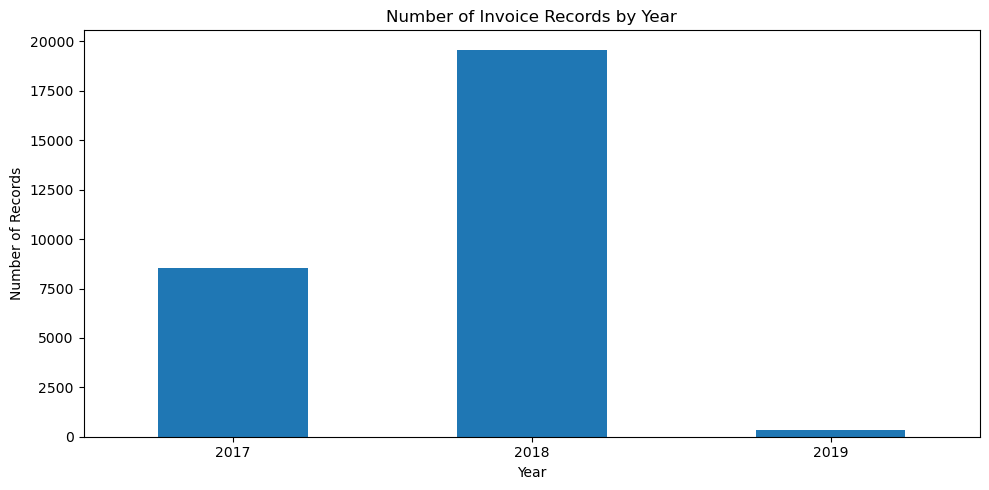

In [13]:
print("Earliest Invoice Date:", df["invoice_date"].min())
print("Latest Invoice Date:", df["invoice_date"].max())

print("\nNumber of records by year:")
print(df["invoice_date"].dt.year.value_counts().sort_index())

# Visualize invoice records by year
yearly_records = df["invoice_date"].dt.year.value_counts().sort_index()

plt.figure(figsize=(10, 5))
yearly_records.plot(kind="bar")
plt.title("Number of Invoice Records by Year")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 8.2 Job Card Date Analysis

Job card dates are analysed to understand the time period covered by service records and the yearly distribution of recorded job cards. Comparing job card dates with invoice dates helps understand the timeline of service activities.


Earliest Job Card Date: 2017-05-30 00:00:00
Latest Job Card Date: 2019-01-06 00:00:00

Number of records by job card year:
job_card_date
2017     8577
2018    19554
2019      351
Name: count, dtype: int64


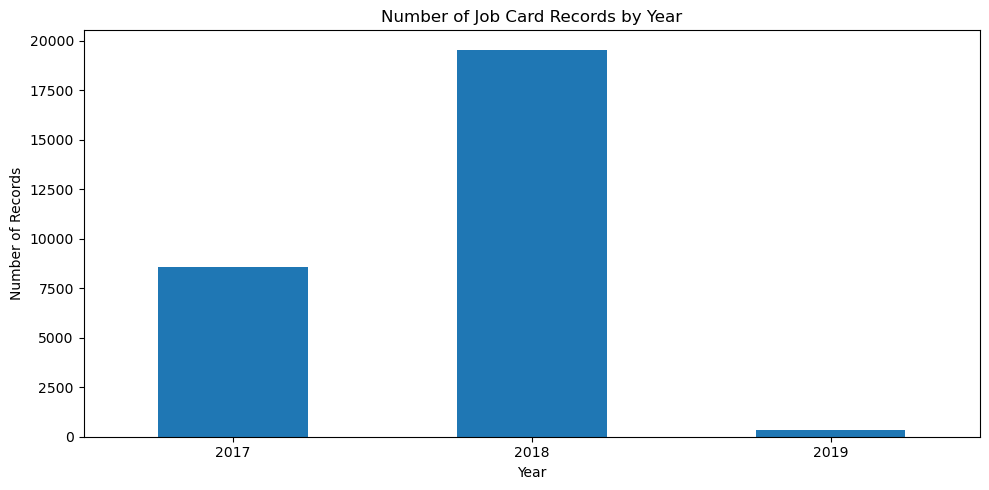

In [14]:
print("Earliest Job Card Date:", df["job_card_date"].min())
print("Latest Job Card Date:", df["job_card_date"].max())

print("\nNumber of records by job card year:")
print(df["job_card_date"].dt.year.value_counts().sort_index())

# Visualize job card records by year
yearly_job_cards = (
    df["job_card_date"].dt.year.value_counts().sort_index()
)

plt.figure(figsize=(10, 5))
yearly_job_cards.plot(kind="bar")
plt.title("Number of Job Card Records by Year")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Job Card Date Analysis Findings**

The dataset covers job card records from May 2017 to January 2019. The highest number of records was observed in 2018, with 19,554 records, followed by 8,577 records in 2017. Only 351 records belong to 2019 because the available data ends on January 6, 2019. The yearly distribution is similar to the invoice date analysis.


### 8.3 Most Frequently Recorded Service Items

This analysis identifies the most frequently recorded service items in the dataset using the `invoice_line_text` column. Understanding service item frequency helps identify commonly recorded service activities that may be useful for inventory planning. Since the dataset does not contain an explicit spare-parts quantity column, record frequency is used as an indicator rather than actual spare-parts consumption.


Total unique service items: 495

Top 15 Most Frequently Recorded Service Items:


,Service Item,Record Count
0,ENGINE OIL,3802
1,CHAIN LUBRICATION,3441
2,GENERAL SERVICE,2142
3,AIR FILTER,1715
4,3M OIL,1628
5,CONSUMABLES,1595
6,POLISH,1245
7,DISC OIL,991
8,BRAKE SHOE,965
9,OIL FILTER,821


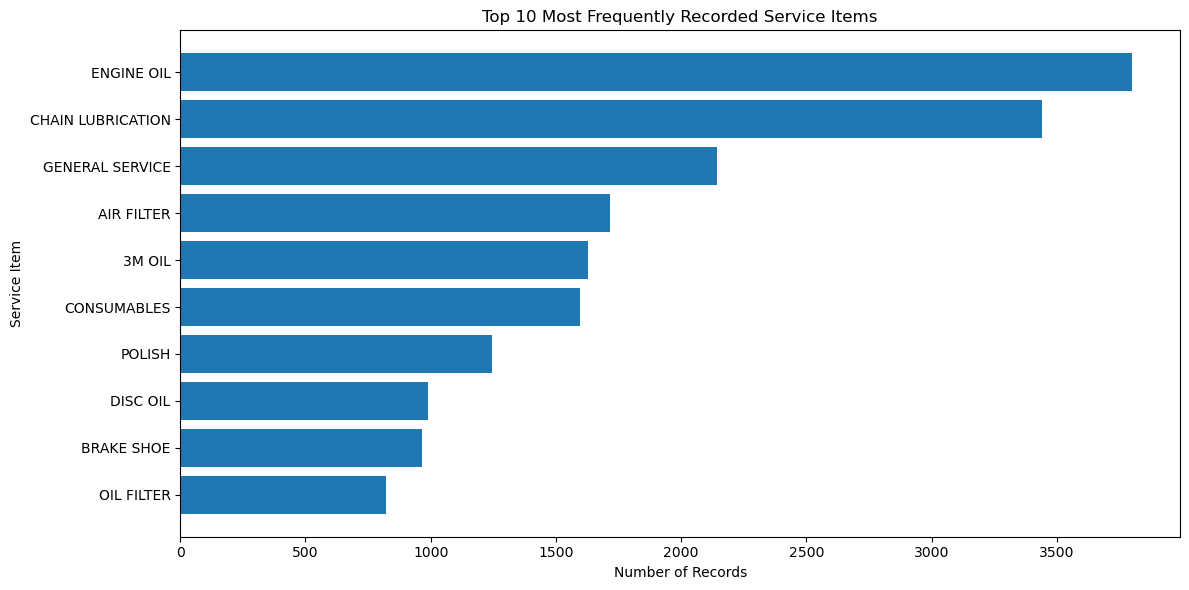

In [15]:
# 8.3 Most Frequently Recorded Service Items

service_item_counts = (
    df["invoice_line_text"]
    .value_counts()
    .reset_index()
)

service_item_counts.columns = ["Service Item", "Record Count"]

print("Total unique service items:", df["invoice_line_text"].nunique())
print("\nTop 15 Most Frequently Recorded Service Items:")
display(service_item_counts.head(15))

# Plot top 10 service items
top_10_items = service_item_counts.head(10).sort_values(
    by="Record Count",
    ascending=True
)

plt.figure(figsize=(12, 6))
plt.barh(top_10_items["Service Item"], top_10_items["Record Count"])
plt.title("Top 10 Most Frequently Recorded Service Items")
plt.xlabel("Number of Records")
plt.ylabel("Service Item")
plt.tight_layout()
plt.show()

**Service Item Analysis Findings**

The dataset contains 495 unique recorded service item entries. ENGINE OIL is the most frequently recorded item, with 3,802 records, followed by CHAIN LUBRICATION with 3,441 records and GENERAL SERVICE with 2,142 records. AIR FILTER and 3M OIL are also frequently recorded. These findings help identify common service activities for inventory planning. However, record frequency does not represent the actual quantity of spare parts consumed.


### 8.4 Vehicle Model Analysis

This analysis examines the distribution of service records across different vehicle models. Identifying vehicle models with the highest number of records helps understand service activity patterns and supports vehicle-specific inventory planning.


Total unique vehicle models: 28

Top 15 Vehicle Models by Record Count:


,Vehicle Model,Record Count
0,BAJAJ PULSAR 150,8633
1,BAJAJ AVENGER STREET 220,4212
2,BAJAJ PULSAR 220,2655
3,BAJAJ PULSAR 180,2252
4,BAJAJ PULSAR NS 200,2204
5,BAJAJ CT 100,1432
6,BAJAJ DISCOVER 125,1346
7,BAJAJ AVENGER STREET,1112
8,BAJAJ PLATINA,844
9,BAJAJ V150,686


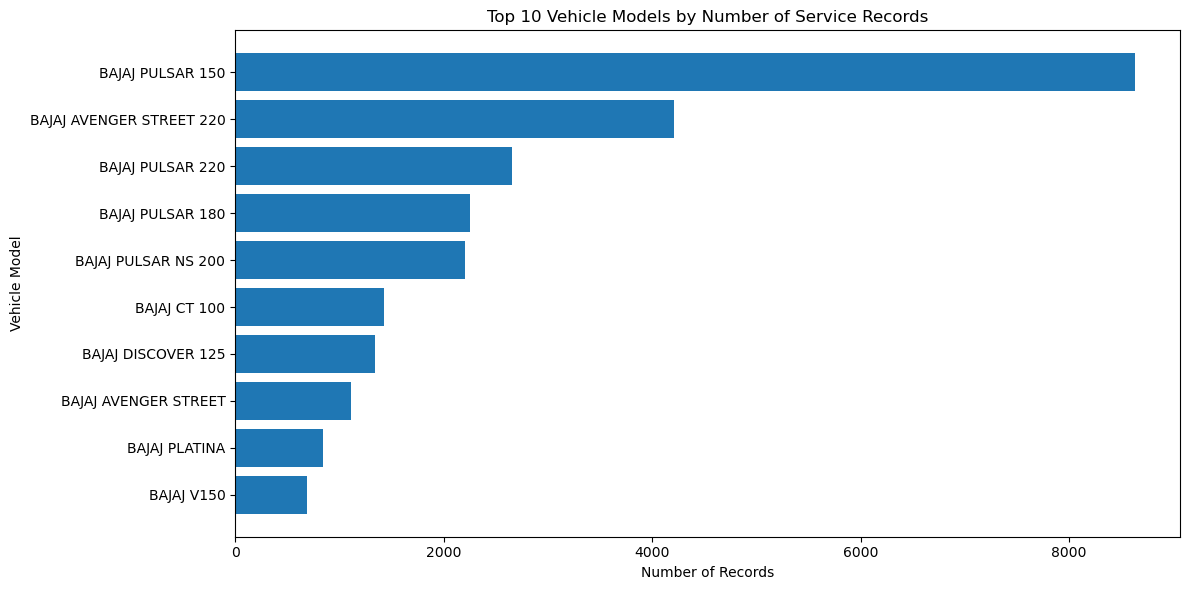

In [16]:
# 8.4 Vehicle Model Analysis

vehicle_model_counts = (
    df["vehicle_model"]
    .value_counts()
    .reset_index()
)

vehicle_model_counts.columns = ["Vehicle Model", "Record Count"]

print("Total unique vehicle models:", df["vehicle_model"].nunique())
print("\nTop 15 Vehicle Models by Record Count:")
display(vehicle_model_counts.head(15))

# Plot top 10 vehicle models
top_10_models = vehicle_model_counts.head(10).sort_values(
    by="Record Count",
    ascending=True
)

plt.figure(figsize=(12, 6))
plt.barh(
    top_10_models["Vehicle Model"].astype(str),
    top_10_models["Record Count"]
)
plt.title("Top 10 Vehicle Models by Number of Service Records")
plt.xlabel("Number of Records")
plt.ylabel("Vehicle Model")
plt.tight_layout()
plt.show()

**Vehicle Model Analysis Findings**

The dataset contains 28 unique vehicle models. BAJAJ PULSAR 150 has the highest number of service records, with 8,633 records, followed by BAJAJ AVENGER STREET 220 with 4,212 records and BAJAJ PULSAR 220 with 2,655 records. BAJAJ PULSAR 180 and BAJAJ PULSAR NS 200 also have a considerable number of records. These results indicate that service activity is concentrated among certain vehicle models, which can help guide vehicle-specific inventory planning.


### 8.5 Monthly Invoice Trends

This analysis examines monthly invoice record counts to identify changes in service activity over time. Monthly trends can help understand periods with higher or lower recorded service activity and provide a foundation for time-series forecasting. These counts represent invoice records, not actual spare-parts quantities. The first month (May 2017) and last month (January 2019) are partial months because the dataset starts on May 30, 2017 and ends on January 6, 2019.


Monthly Invoice Record Counts:


,Record Count
invoice_date,
2017-05-01,11
2017-06-01,1346
2017-07-01,1178
2017-08-01,973
2017-09-01,1264
2017-10-01,1054
2017-11-01,1376
2017-12-01,1345
2018-01-01,998


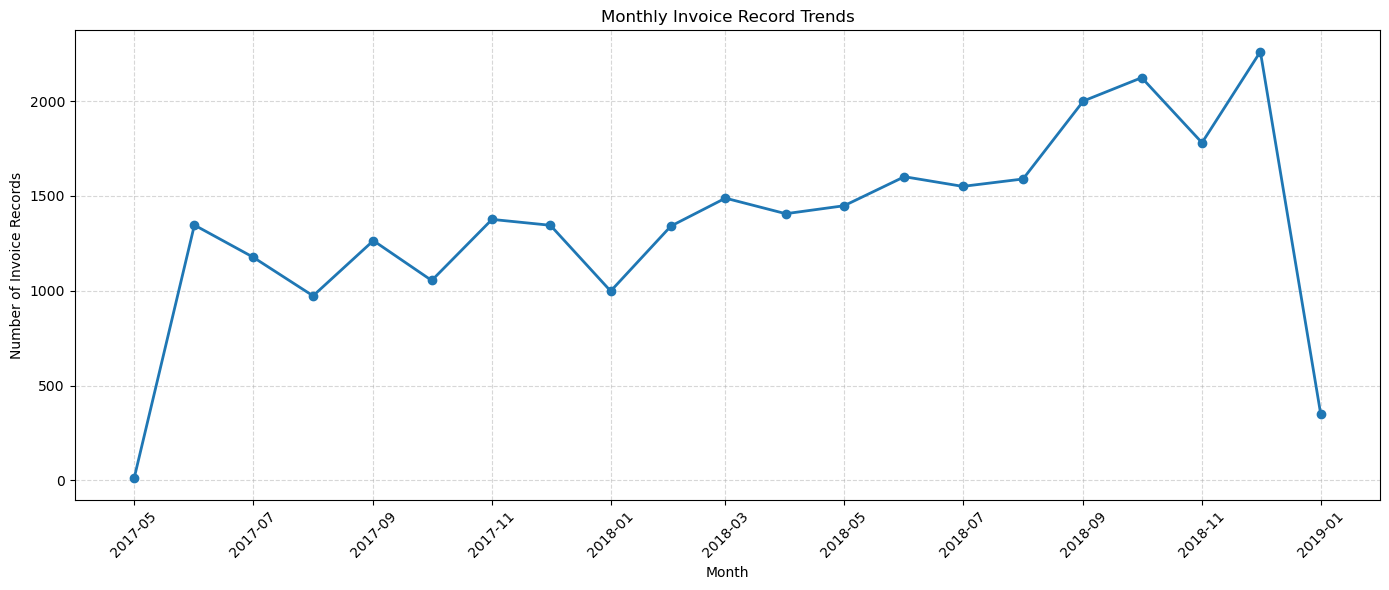

In [17]:
monthly_invoice_counts = (
    df.set_index("invoice_date")
    .resample("MS")
    .size()
)

print("Monthly Invoice Record Counts:")
display(monthly_invoice_counts.to_frame(name="Record Count"))

# Plot monthly invoice trends
plt.figure(figsize=(14, 6))
plt.plot(
    monthly_invoice_counts.index,
    monthly_invoice_counts.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Invoice Record Trends")
plt.xlabel("Month")
plt.ylabel("Number of Invoice Records")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Monthly Invoice Trends Findings**

The monthly invoice analysis shows variations in recorded service activity over time. December 2018 had the highest number of invoice records, with 2,260 records, followed by October 2018 with 2,123 records and September 2018 with 2,000 records. May 2017 had only 11 records, as the available dataset begins on May 30, 2017. January 2019 contains 351 records because the dataset ends on January 6, 2019. These trends describe invoice record frequency and do not represent actual spare-parts quantities consumed.


### 8.6 Vehicle Kilometre Reading Analysis

This analysis examines the distribution of vehicle kilometre readings in the dataset. Understanding the kilometre readings helps identify the usage levels of vehicles recorded for service. This information may support service planning and vehicle maintenance decisions. The analysis uses descriptive statistics and visualisations to understand the distribution of recorded kilometre readings.


Vehicle Kilometre Reading Summary:


,Kilometre Reading
count,28482.000000
mean,19348.003827
std,25246.722306
min,0.000000
25%,3988.000000
50%,12420.500000
75%,27905.000000
max,610112.000000


Minimum Kilometre Reading: 0
Maximum Kilometre Reading: 610112


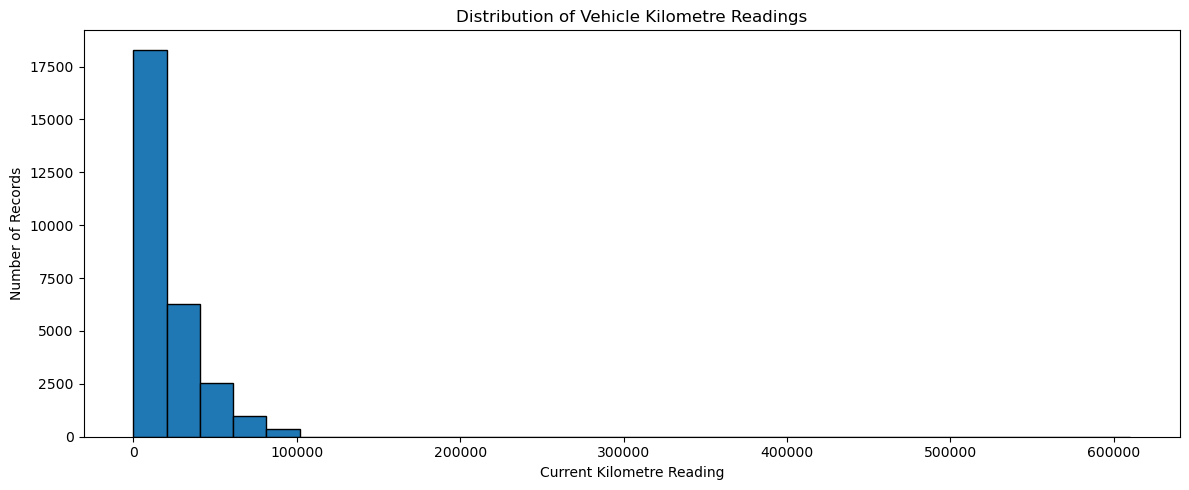

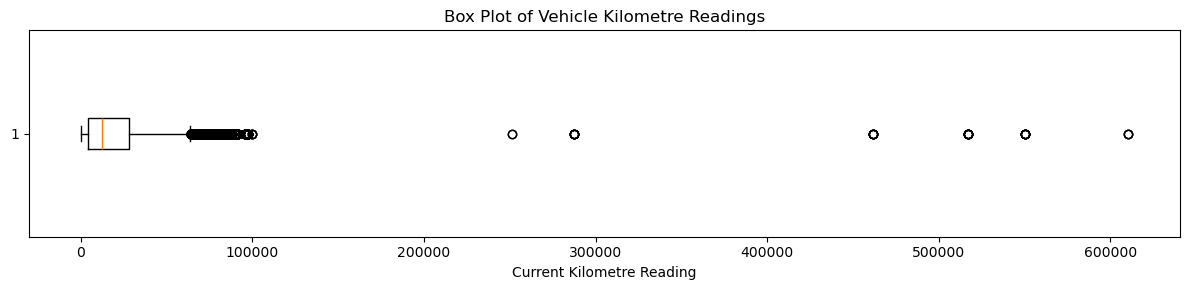

In [18]:
# Display descriptive statistics
print("Vehicle Kilometre Reading Summary:")
display(df["current_km_reading"].describe().to_frame(name="Kilometre Reading"))

# Display minimum and maximum readings
print("Minimum Kilometre Reading:", df["current_km_reading"].min())
print("Maximum Kilometre Reading:", df["current_km_reading"].max())

# Plot 1: Distribution of kilometre readings
plt.figure(figsize=(12, 5))
plt.hist(df["current_km_reading"].dropna(), bins=30, edgecolor="black")
plt.title("Distribution of Vehicle Kilometre Readings")
plt.xlabel("Current Kilometre Reading")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Plot 2: Box plot of kilometre readings
plt.figure(figsize=(12, 3))
plt.boxplot(df["current_km_reading"].dropna(), vert=False)
plt.title("Box Plot of Vehicle Kilometre Readings")
plt.xlabel("Current Kilometre Reading")
plt.tight_layout()
plt.show()

**Vehicle Kilometre Reading Analysis Findings**

The dataset contains 28,482 vehicle service records. The average kilometre reading is approximately 19,348 km, while the median reading is 12,420.5 km. The minimum reading is 0 km, and the maximum is 610,112 km. The mean is higher than the median, indicating a right-skewed distribution influenced by some high kilometre readings. These findings help understand the usage levels of vehicles recorded in the service dataset.


### 8.7 Key EDA Findings

The exploratory data analysis identified several important patterns in the service dataset:

* **Invoice Trends:** The dataset covers invoice records from May 30, 2017 to January 6, 2019. December 2018 had the highest monthly record count. May 2017 and January 2019 are partial months.
* **Service Items:** ENGINE OIL is the most frequently recorded service item, followed by CHAIN LUBRICATION and GENERAL SERVICE.
* **Vehicle Models:** BAJAJ PULSAR 150 has the highest number of service records among the vehicle models.
* **Kilometre Readings:** The average vehicle kilometre reading is approximately 19,348 km, with some records showing considerably higher readings.
* **Inventory Planning:** Service item frequency and monthly record patterns may help identify commonly recorded service items and periods of higher service activity.

**Limitation:** The dataset does not contain an explicit spare-parts quantity column. Therefore, service record frequency will be used as a proxy for analysis, not as a direct measure of actual spare-parts consumption.


## 9. Feature Engineering

Feature engineering involves creating useful features from existing dataset columns to support further analysis and forecasting. In this project, year and month information will be extracted from invoice dates, and monthly service record counts will be prepared for item-level demand analysis. These features will help identify service activity patterns over time.


### 9.1 Extract Year and Month

The year and month are extracted from the invoice date to understand service activity across different time periods. These features will be used in monthly trend analysis and forecasting preparation.


In [19]:
df["invoice_year"] = df["invoice_date"].dt.year
df["invoice_month"] = df["invoice_date"].dt.month
df["invoice_year_month"] = df["invoice_date"].dt.to_period("M")

print("Dataset shape after feature extraction:", df.shape)

print("\nSample records with new date features:")
display(
    df[
        [
            "invoice_date",
            "invoice_year",
            "invoice_month",
            "invoice_year_month",
            "invoice_line_text"
        ]
    ].head(10)
)

print("\nRecords by invoice year and month:")
monthly_record_counts = (
    df.groupby("invoice_year_month")
      .size()
      .reset_index(name="Record Count")
)

display(monthly_record_counts)

Dataset shape after feature extraction: (28482, 10)

Sample records with new date features:


,invoice_date,invoice_year,invoice_month,invoice_year_month,invoice_line_text
0,2017-05-30,2017,5,2017-05,ENGINE OIL
1,2017-06-02,2017,6,2017-06,ENGINE OIL
2,2017-06-02,2017,6,2017-06,POLISH
3,2017-06-02,2017,6,2017-06,CONSUMABLES
4,2017-06-02,2017,6,2017-06,COOLANT OIL
5,2017-06-02,2017,6,2017-06,CHAIN LUBRICATION
6,2017-06-02,2017,6,2017-06,4 WAY SWITCH
7,2017-05-31,2017,5,2017-05,ENGINE OIL
8,2017-05-31,2017,5,2017-05,3M OIL
9,2017-05-31,2017,5,2017-05,CHAIN LUBRICATION



Records by invoice year and month:


,invoice_year_month,Record Count
0,2017-05,11
1,2017-06,1346
2,2017-07,1178
3,2017-08,973
4,2017-09,1264
5,2017-10,1054
6,2017-11,1376
7,2017-12,1345
8,2018-01,998
9,2018-02,1341


### 9.2 Create Monthly Time Features

Monthly time features are created by grouping invoice records by year and month. This aggregation converts individual service records into a monthly time series that can be used to examine changes in service activity and establish a baseline forecasting model.


In [20]:
monthly_service_records = (
    df.groupby("invoice_year_month")
      .size()
      .reset_index(name="Record Count")
)

monthly_service_records["month_start"] = (
    monthly_service_records["invoice_year_month"]
    .dt.to_timestamp()
)

monthly_service_records["month_number"] = (
    monthly_service_records["month_start"].dt.month
)

monthly_service_records["year"] = (
    monthly_service_records["month_start"].dt.year
)

print("Monthly time-series dataset:")
display(monthly_service_records)

print("\nNumber of monthly observations:", len(monthly_service_records))
print(
    "Date range:",
    monthly_service_records["month_start"].min(),
    "to",
    monthly_service_records["month_start"].max()
)

Monthly time-series dataset:


,invoice_year_month,Record Count,month_start,month_number,year
0,2017-05,11,2017-05-01,5,2017
1,2017-06,1346,2017-06-01,6,2017
2,2017-07,1178,2017-07-01,7,2017
3,2017-08,973,2017-08-01,8,2017
4,2017-09,1264,2017-09-01,9,2017
5,2017-10,1054,2017-10-01,10,2017
6,2017-11,1376,2017-11-01,11,2017
7,2017-12,1345,2017-12-01,12,2017
8,2018-01,998,2018-01-01,1,2018
9,2018-02,1341,2018-02-01,2,2018



Number of monthly observations: 21
Date range: 2017-05-01 00:00:00 to 2019-01-01 00:00:00


### 9.3 Prepare Item-Level Analysis

The dataset is grouped by service item to calculate the number of records associated with each item. This analysis identifies frequently recorded service items that may be useful for inventory planning. Since the dataset does not contain an explicit spare-parts quantity column, record frequency is used as a proxy for service item activity rather than actual spare-parts consumption.


In [21]:
item_level_records = (
    df.groupby("invoice_line_text")
      .size()
      .reset_index(name="Record Count")
      .sort_values("Record Count", ascending=False)
      .reset_index(drop=True)
)

print("Total unique service items:", len(item_level_records))
print("\nTop 15 service items by record frequency:")
display(item_level_records.head(15))

Total unique service items: 495

Top 15 service items by record frequency:


,invoice_line_text,Record Count
0,ENGINE OIL,3802
1,CHAIN LUBRICATION,3441
2,GENERAL SERVICE,2142
3,AIR FILTER,1715
4,3M OIL,1628
5,CONSUMABLES,1595
6,POLISH,1245
7,DISC OIL,991
8,BRAKE SHOE,965
9,OIL FILTER,821


### 9.4 Validate Features

The engineered features are validated to confirm that the year and month columns contain valid values and that the monthly and item-level aggregations account for all service records. This validation helps ensure the prepared data is consistent for the next stage of inventory demand analysis and forecasting.


In [22]:
print("Dataset shape:", df.shape)

print("\nMissing values in engineered features:")
display(
    df[
        ["invoice_year", "invoice_month", "invoice_year_month"]
    ].isnull().sum().to_frame(name="Missing Values")
)

print("\nMonthly record count total:", monthly_service_records["Record Count"].sum())
print("Original dataset record count:", len(df))

print("\nUnique service items in item-level analysis:", len(item_level_records))
print("Total records in item-level analysis:", item_level_records["Record Count"].sum())

# Validate record counts and engineered features
assert monthly_service_records["Record Count"].sum() == len(df)
assert item_level_records["Record Count"].sum() == len(df)
assert df[["invoice_year", "invoice_month", "invoice_year_month"]].isnull().sum().sum() == 0

print("\nFeature validation completed successfully.")

Dataset shape: (28482, 10)

Missing values in engineered features:


,Missing Values
invoice_year,0
invoice_month,0
invoice_year_month,0



Monthly record count total: 28482
Original dataset record count: 28482

Unique service items in item-level analysis: 495
Total records in item-level analysis: 28482

Feature validation completed successfully.


## 10. Inventory Demand Analysis

Inventory demand analysis is performed to understand the frequency of recorded service items and how service activity changes over time. The analysis identifies frequently recorded items and examines their monthly record patterns to support inventory planning. Since the dataset does not contain an explicit spare-parts quantity column, the number of service records is used as a proxy for item activity rather than actual spare-parts consumption.


### 10.1 Define the Available Demand Measure

The dataset does not include a dedicated quantity or spare-parts consumption column. Therefore, this project defines the available demand measure as the number of records associated with each service item. This measure indicates how frequently an item is recorded in service transactions but does not represent the actual quantity consumed or required for inventory replenishment.


In [23]:
demand_measure = (
    df.groupby("invoice_line_text")
      .size()
      .reset_index(name="Record Frequency")
      .sort_values("Record Frequency", ascending=False)
      .reset_index(drop=True)
)

print("Demand measure: Service item record frequency")
print("Total service records:", demand_measure["Record Frequency"].sum())
print("Unique service items:", demand_measure["invoice_line_text"].nunique())

print("\nTop 10 items by recorded frequency:")
display(demand_measure.head(10))

Demand measure: Service item record frequency
Total service records: 28482
Unique service items: 495

Top 10 items by recorded frequency:


,invoice_line_text,Record Frequency
0,ENGINE OIL,3802
1,CHAIN LUBRICATION,3441
2,GENERAL SERVICE,2142
3,AIR FILTER,1715
4,3M OIL,1628
5,CONSUMABLES,1595
6,POLISH,1245
7,DISC OIL,991
8,BRAKE SHOE,965
9,OIL FILTER,821


### 10.2 Analyse Item-Level Record Frequency

Item-level record frequency is analysed to understand how often individual service items appear in the dataset. Descriptive statistics are used to examine the distribution of record frequencies across all unique service items. This helps distinguish frequently recorded items from those appearing less often and supports preliminary inventory planning.


Summary Statistics of Item-Level Record Frequency:


,Record Frequency
count,495.000000
mean,57.539394
std,296.761552
min,1.000000
25%,1.000000
50%,3.000000
75%,14.000000
max,3802.000000



Items with the lowest record frequency:


,invoice_line_text,Record Frequency
485,STOPPER HOLDER,1
486,TANK RUBBER,1
487,BORE,1
488,BORE GASKET,1
489,BRAKE BUSH KIT,1
490,WASHING AND POLISH,1
491,VISIOR WITH LABOUR,1
492,WASHING AND LABOUR,1
493,VISIOR BOTTOM COVER,1
494,FUEL GUAGE OVERHUAL,1



Items with the highest record frequency:


,invoice_line_text,Record Frequency
0,ENGINE OIL,3802
1,CHAIN LUBRICATION,3441
2,GENERAL SERVICE,2142
3,AIR FILTER,1715
4,3M OIL,1628
5,CONSUMABLES,1595
6,POLISH,1245
7,DISC OIL,991
8,BRAKE SHOE,965
9,OIL FILTER,821


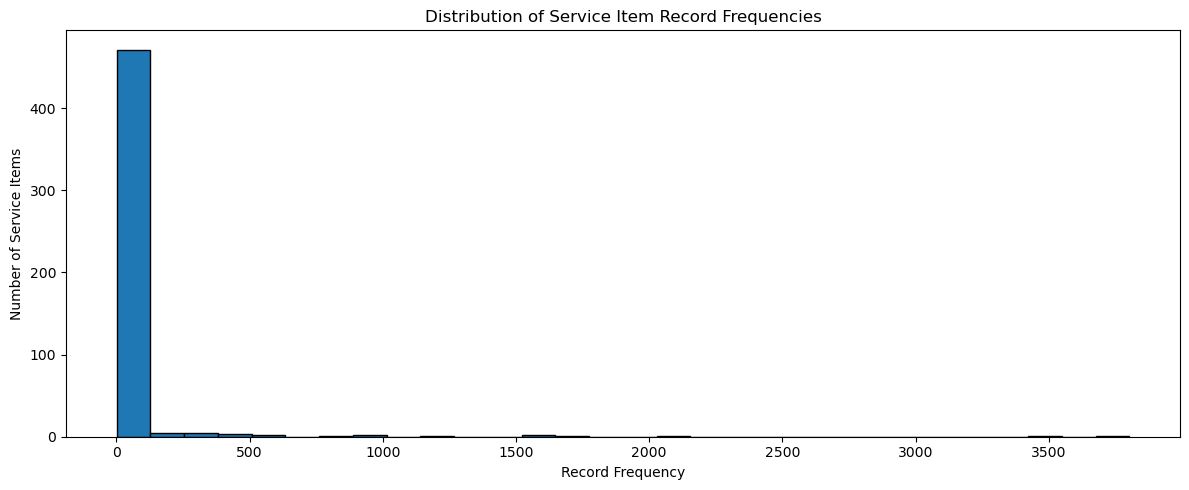

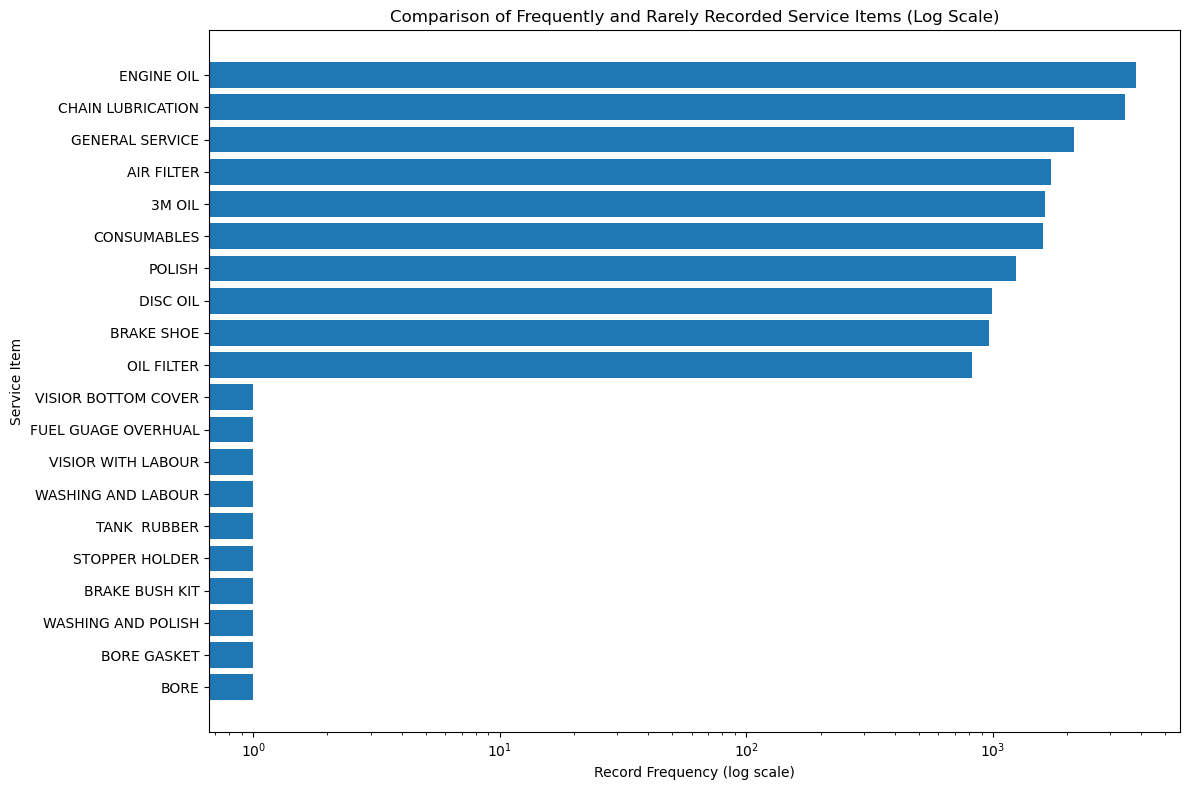

In [24]:
print("Summary Statistics of Item-Level Record Frequency:")
display(demand_measure["Record Frequency"].describe().to_frame(name="Record Frequency"))

print("\nItems with the lowest record frequency:")
display(demand_measure.tail(10))

print("\nItems with the highest record frequency:")
display(demand_measure.head(10))

# Graph 1: Distribution of item-level record frequencies
plt.figure(figsize=(12, 5))
plt.hist(demand_measure["Record Frequency"], bins=30, edgecolor="black")
plt.title("Distribution of Service Item Record Frequencies")
plt.xlabel("Record Frequency")
plt.ylabel("Number of Service Items")
plt.tight_layout()
plt.show()

# Graph 2: Top 10 vs bottom 10 items
top_items = demand_measure.head(10).copy()
top_items["Frequency Group"] = "Top 10"

bottom_items = demand_measure.tail(10).copy()
bottom_items["Frequency Group"] = "Bottom 10"

comparison_items = pd.concat([top_items, bottom_items], ignore_index=True)
comparison_items = comparison_items.sort_values("Record Frequency", ascending=True)

plt.figure(figsize=(12, 8))
plt.barh(
    comparison_items["invoice_line_text"],
    comparison_items["Record Frequency"]
)
plt.title("Comparison of Frequently and Rarely Recorded Service Items (Log Scale)")
plt.xscale("log")
plt.xlabel("Record Frequency (log scale)")
plt.ylabel("Service Item")
plt.tight_layout()
plt.show()

**Item-Level Record Frequency Findings**

The analysis covers 495 unique service items. The average record frequency is 57.54, while the median is only 3, indicating that service record frequencies are unevenly distributed across items. ENGINE OIL has the highest frequency, with 3,802 records, followed by CHAIN LUBRICATION with 3,441 records. Several items appear only once in the dataset. These findings indicate that a small group of items accounts for a substantial share of recorded service activity. Record frequency is used as a proxy and does not represent actual spare-parts consumption.


### 10.3 Identify Frequently Recorded Items

This analysis identifies the most frequently recorded service items to support inventory prioritisation. The top 15 items are examined and visualised in descending order of record frequency. These results can help highlight items that may require closer monitoring, subject to verification against actual spare-parts usage and stock records.


In [25]:
top_15_items = demand_measure.head(15).copy()

print("Top 15 Frequently Recorded Service Items:")
display(top_15_items)

Top 15 Frequently Recorded Service Items:


,invoice_line_text,Record Frequency
0,ENGINE OIL,3802
1,CHAIN LUBRICATION,3441
2,GENERAL SERVICE,2142
3,AIR FILTER,1715
4,3M OIL,1628
5,CONSUMABLES,1595
6,POLISH,1245
7,DISC OIL,991
8,BRAKE SHOE,965
9,OIL FILTER,821


**Key Findings:**

The analysis identifies the top 15 most frequently recorded service items. ENGINE OIL has the highest record frequency, with 3,802 records, followed by CHAIN LUBRICATION with 3,441 records and GENERAL SERVICE with 2,142 records. AIR FILTER and 3M OIL are also frequently recorded items. These results can help prioritise items for further inventory review. However, record frequency represents the number of service records, not the actual quantity of spare parts consumed.


### 10.4 Analyse Demand Patterns Over Time

This section analyses the monthly record frequency of the top five most frequently recorded service items. A month-wise comparison table and line chart are used to observe changes in recorded service activity over time. Since the dataset does not contain an explicit spare-parts quantity column, record frequency is used as a proxy rather than actual spare-parts demand.


Monthly Record Frequency of the Top 5 Service Items:


invoice_line_text,3M OIL,AIR FILTER,CHAIN LUBRICATION,ENGINE OIL,GENERAL SERVICE
month_start,,,,,
2017-05-01,2,0,2,5,1
2017-06-01,88,5,167,179,91
2017-07-01,75,34,158,172,91
2017-08-01,64,52,138,146,79
2017-09-01,81,77,178,187,108
2017-10-01,68,70,138,158,96
2017-11-01,82,89,178,191,111
2017-12-01,85,112,202,213,123
2018-01-01,63,77,138,154,91


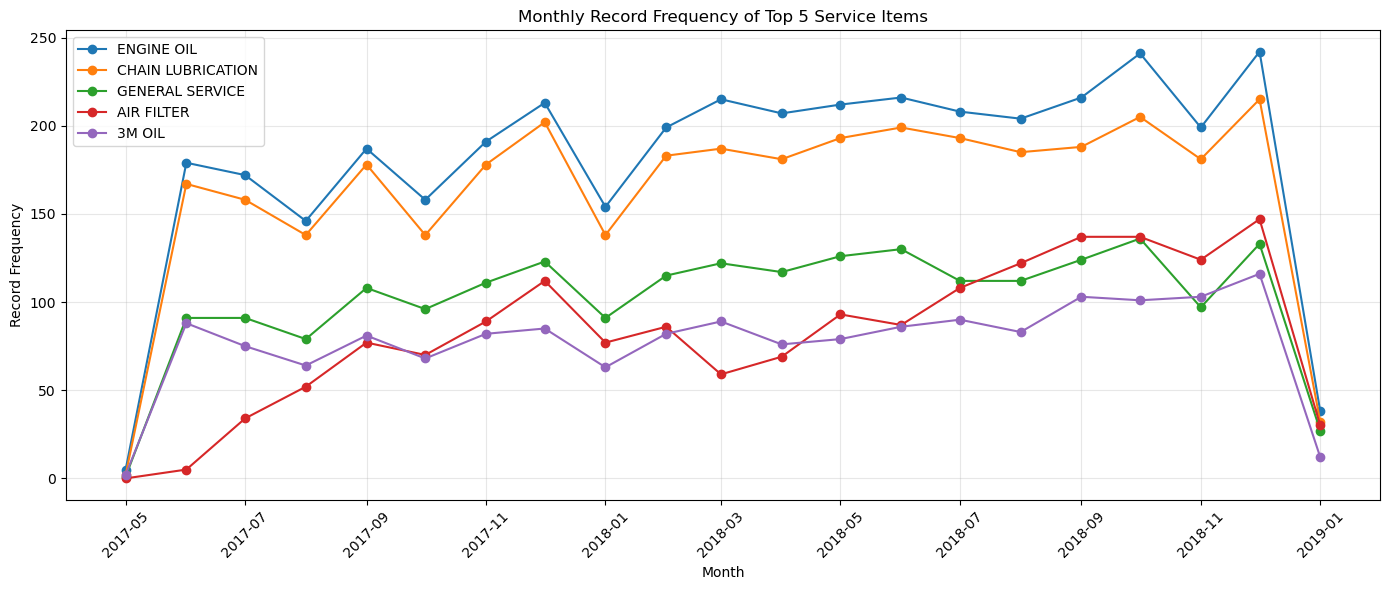

In [26]:
monthly_item_frequency = (
    df.groupby(["invoice_year_month", "invoice_line_text"])
      .size()
      .reset_index(name="Record Frequency")
)

monthly_item_frequency["month_start"] = (
    monthly_item_frequency["invoice_year_month"].dt.to_timestamp()
)

# Select the top 5 items by overall record frequency
top_5_items = demand_measure.head(5)["invoice_line_text"].tolist()

top_items_monthly = monthly_item_frequency[
    monthly_item_frequency["invoice_line_text"].isin(top_5_items)
]

# Create a month-wise comparison table
monthly_pivot = (
    top_items_monthly.pivot(
        index="month_start",
        columns="invoice_line_text",
        values="Record Frequency"
    )
    .fillna(0)
    .astype(int)
)

print("Monthly Record Frequency of the Top 5 Service Items:")
display(monthly_pivot)

# Plot monthly patterns
plt.figure(figsize=(14, 6))

for item in top_5_items:
    if item in monthly_pivot.columns:
        plt.plot(
            monthly_pivot.index,
            monthly_pivot[item],
            marker="o",
            label=item
        )

plt.title("Monthly Record Frequency of Top 5 Service Items")
plt.xlabel("Month")
plt.ylabel("Record Frequency")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Key Findings:**

The monthly analysis shows variations in the record frequency of the five most frequently recorded service items. ENGINE OIL consistently has a high record frequency and reaches 242 records in December 2018. CHAIN LUBRICATION also records a high frequency, reaching 215 records in December 2018. AIR FILTER records generally increase during the observed period, reaching 147 records in December 2018. These patterns can help identify service items for closer inventory monitoring. However, the results represent service-record frequency rather than actual spare-parts consumption. The final month, January 2019, covers only part of the month, so its figures should not be directly compared with complete months.


### 10.5 Spare-Part Description Classification

The invoice line descriptions are provisionally classified into service or labour items, consumables, and possible spare parts. This classification uses keyword-based rules to support preliminary inventory analysis. Since the dataset does not provide an official item category, the assigned categories require business verification before they are used for inventory decisions.

In [27]:
# Create a copy of the item-level frequency table

all_item_descriptions = demand_measure.rename(
    columns={
        "invoice_line_text": "Invoice Line Description"
    }
).copy()


# Define a provisional item classification function

def classify_description(description):

    item = str(description).upper().strip()
    words = item.split()

    # Identify likely spare parts that contain the word OIL
    if "OIL FILTER" in item or "OIL SEAL" in item:
        return "Possible Spare Part / Needs Review"

    service_terms = [
        "SERVICE",
        "LABOUR",
        "LUBRICATION",
        "CHECK",
        "WASHING",
        "FITTING CHARGE",
        "OVERHAUL",
        "OVERHUAL"
    ]

    # Classify services and labour-related descriptions
    if any(term in item for term in service_terms):
        return "Service / Labour"

    # Match OIL as a separate word, not as part of words like COIL
    consumable_terms = [
        "POLISH",
        "CONSUMABLE",
        "GREASE",
        "COOLANT"
    ]

    if (
        "OIL" in words
        or any(term in item for term in consumable_terms)
    ):
        return "Consumable / Needs Confirmation"

    return "Possible Spare Part / Needs Review"


# Apply provisional classification

all_item_descriptions["Provisional Category"] = (
    all_item_descriptions["Invoice Line Description"]
    .apply(classify_description)
)


# Summarise descriptions and record frequency by category

category_summary = (
    all_item_descriptions
    .groupby("Provisional Category")
    .agg(
        Unique_Descriptions=("Invoice Line Description", "count"),
        Total_Record_Frequency=("Record Frequency", "sum")
    )
    .reset_index()
    .sort_values("Total_Record_Frequency", ascending=False)
)

print("Provisional Item Category Summary:")
display(category_summary)


# Display the top 10 descriptions in each category

for category in all_item_descriptions["Provisional Category"].unique():

    print(f"\nTop 10 items in category: {category}")

    category_items = (
        all_item_descriptions[
            all_item_descriptions["Provisional Category"] == category
        ]
        .sort_values("Record Frequency", ascending=False)
        .head(10)
    )

    display(category_items)


# Validate classification totals

print(
    "\nTotal descriptions:",
    all_item_descriptions["Invoice Line Description"].nunique()
)

print(
    "Total record frequency:",
    all_item_descriptions["Record Frequency"].sum()
)

print("Original dataset records:", len(df))
       




Provisional Item Category Summary:


,Provisional Category,Unique_Descriptions,Total_Record_Frequency
1,Possible Spare Part / Needs Review,441,12019
0,Consumable / Needs Confirmation,20,9475
2,Service / Labour,34,6988



Top 10 items in category: Consumable / Needs Confirmation


,Invoice Line Description,Record Frequency,Provisional Category
0,ENGINE OIL,3802,Consumable / Needs Confirmation
4,3M OIL,1628,Consumable / Needs Confirmation
5,CONSUMABLES,1595,Consumable / Needs Confirmation
6,POLISH,1245,Consumable / Needs Confirmation
7,DISC OIL,991,Consumable / Needs Confirmation
31,FORK OIL,95,Consumable / Needs Confirmation
41,COOLANT OIL,70,Consumable / Needs Confirmation
121,OIL LENSE,15,Consumable / Needs Confirmation
149,DISC OIL TOPUP,10,Consumable / Needs Confirmation
180,COOLANT OIL TOP UP,6,Consumable / Needs Confirmation



Top 10 items in category: Service / Labour


,Invoice Line Description,Record Frequency,Provisional Category
1,CHAIN LUBRICATION,3441,Service / Labour
2,GENERAL SERVICE,2142,Service / Labour
12,AIR FILTER CHECKUP,467,Service / Labour
18,CHAIN OVERHAUL,284,Service / Labour
21,CLUTCH OVERHUAL,163,Service / Labour
23,LABOUR,131,Service / Labour
35,DISC OVERHUAL,79,Service / Labour
40,FORK OVERHUAL,72,Service / Labour
57,WASHING,52,Service / Labour
62,ENGINE LABOUR,49,Service / Labour



Top 10 items in category: Possible Spare Part / Needs Review


,Invoice Line Description,Record Frequency,Provisional Category
3,AIR FILTER,1715,Possible Spare Part / Needs Review
8,BRAKE SHOE,965,Possible Spare Part / Needs Review
9,OIL FILTER,821,Possible Spare Part / Needs Review
10,DISC PAD,575,Possible Spare Part / Needs Review
11,WHEEL RUBBER,521,Possible Spare Part / Needs Review
13,SPARK PLUG,421,Possible Spare Part / Needs Review
14,CHAIN SPROCKET,396,Possible Spare Part / Needs Review
15,SPROCKET RUBBER,347,Possible Spare Part / Needs Review
16,CLUTCH CABLE,341,Possible Spare Part / Needs Review
17,SPROCKET BEARING,314,Possible Spare Part / Needs Review



Total descriptions: 495
Total record frequency: 28482
Original dataset records: 28482


### 10.6 Selected Spare-Part Monthly Record Frequency

Ten frequently recorded possible spare-part descriptions are selected for monthly analysis. The invoice records are grouped by month to examine how frequently each selected item appears over time. The displayed table includes the available partial boundary months (May 2017 and January 2019). These partial months are excluded from forecasting model training and evaluation. Since the dataset does not contain item quantities, the calculated values represent invoice-line record frequency rather than actual spare-part consumption.


In [28]:
# Select ten possible spare-part descriptions for monthly analysis

selected_spare_parts = [
    "AIR FILTER",
    "BRAKE SHOE",
    "CHAIN SPROCKET",
    "CLUTCH ASSEMBLY",
    "CLUTCH CABLE",
    "DISC PAD",
    "SPARK PLUG",
    "SPROCKET BEARING",
    "SPROCKET RUBBER",
    "WHEEL RUBBER"
]


# Filter records for the selected items

part_month_data = df[
    df["invoice_line_text"].isin(selected_spare_parts)
].copy()


# Extract month from the invoice date

part_month_data["Month"] = (
    part_month_data["invoice_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)


# Calculate monthly record frequency

monthly_part_pivot = (
    part_month_data
    .groupby(["Month", "invoice_line_text"])
    .size()
    .unstack(fill_value=0)
)


# Create a complete monthly date range

start_month = (
    df["invoice_date"].min()
    .to_period("M")
    .to_timestamp()
)

end_month = (
    df["invoice_date"].max()
    .to_period("M")
    .to_timestamp()
)

full_month_index = pd.date_range(
    start=start_month,
    end=end_month,
    freq="MS"
)


# Include all selected items and months

monthly_part_pivot_complete = monthly_part_pivot.reindex(
    index=full_month_index,
    columns=selected_spare_parts,
    fill_value=0
)

monthly_part_pivot_complete.index.name = "Month"


# Display the monthly record-frequency table

print("Monthly Spare-Part Record Frequency:")
display(monthly_part_pivot_complete)


# Validate the monthly totals

original_selected_records = int(
    df["invoice_line_text"].isin(selected_spare_parts).sum()
)

monthly_selected_records = int(
    monthly_part_pivot_complete.to_numpy().sum()
)

print("\nOriginal selected-item records:", original_selected_records)
print("Monthly pivot records:", monthly_selected_records)
print(
    "Difference:",
    original_selected_records - monthly_selected_records
)

assert original_selected_records == monthly_selected_records, (
    "Validation failed: monthly totals do not match the original data."
)

print("Validation successful: monthly totals match the original dataset.")

Monthly Spare-Part Record Frequency:


invoice_line_text,AIR FILTER,BRAKE SHOE,CHAIN SPROCKET,CLUTCH ASSEMBLY,CLUTCH CABLE,DISC PAD,SPARK PLUG,SPROCKET BEARING,SPROCKET RUBBER,WHEEL RUBBER
Month,,,,,,,,,,
2017-05-01,0,0,0,0,0,0,0,0,0,0
2017-06-01,5,44,9,10,16,26,9,1,0,34
2017-07-01,34,35,19,6,22,28,11,1,0,31
2017-08-01,52,29,15,9,15,19,9,0,0,16
2017-09-01,77,36,11,12,25,23,18,0,0,26
2017-10-01,70,41,19,8,11,15,8,0,0,19
2017-11-01,89,51,17,8,15,33,14,2,0,29
2017-12-01,112,47,14,11,17,31,6,0,0,43
2018-01-01,77,38,18,3,6,24,8,1,0,26



Original selected-item records: 5807
Monthly pivot records: 5807
Difference: 0
Validation successful: monthly totals match the original dataset.


## 11. Forecasting Approach

This section establishes a suitable forecasting approach for analysing service activity at NewX Services. The objective is to examine historical monthly service-record patterns and estimate future record frequency to support preliminary inventory planning. Since the dataset does not contain an explicit spare-parts quantity field, monthly service-record frequency is used as a proxy measure rather than actual spare-parts demand. The forecasting results will be interpreted with this limitation in mind.


### 11.1 Define the Forecasting Objective

The objective is to forecast monthly service-record frequency using historical invoice records. This analysis will help identify broad changes in service activity and provide preliminary information for planning. The forecast should not be interpreted as a direct estimate of spare-parts quantities because actual consumption data is unavailable.


In [29]:
print("FORECASTING OBJECTIVE")
print("-" * 40)

print("Objective: Forecast monthly service-record frequency.")

print(
    "Historical period:",
    monthly_service_records["month_start"].min().strftime("%Y-%m"),
    "to",
    monthly_service_records["month_start"].max().strftime("%Y-%m")
)

print(
    "Number of monthly observations:",
    len(monthly_service_records)
)

print(
    "Total service records:",
    monthly_service_records["Record Count"].sum()
)

print("\nImportant Limitation:")
print(
    "The dataset does not contain actual spare-parts quantities. "
    "Therefore, the forecast represents monthly service-record "
    "frequency, not actual spare-parts consumption."
)

FORECASTING OBJECTIVE
----------------------------------------
Objective: Forecast monthly service-record frequency.
Historical period: 2017-05 to 2019-01
Number of monthly observations: 21
Total service records: 28482

Important Limitation:
The dataset does not contain actual spare-parts quantities. Therefore, the forecast represents monthly service-record frequency, not actual spare-parts consumption.


### 11.2 Select a Suitable Forecasting Target

The dataset does not contain a dedicated spare-parts quantity or consumption column. Therefore, monthly invoice-record frequency is selected as the forecasting target for this project. The target represents the number of service records recorded per month, not the actual quantity of spare parts consumed. This target provides a measurable way to analyse historical service activity and estimate future monthly record frequency. The limitation will be considered when interpreting the forecasting results and making inventory-related recommendations.


In [30]:
forecast_data = monthly_service_records[
    ["month_start", "Record Count"]
].copy()

forecast_data = forecast_data.sort_values(
    "month_start"
).reset_index(drop=True)

forecast_data = forecast_data.rename(
    columns={"Record Count": "Monthly Record Frequency"}
)

print("Monthly Forecasting Dataset:")
display(forecast_data)

print("\nForecasting Target Validation")
print("-" * 35)
print("Monthly observations:", len(forecast_data))
print("First month:", forecast_data["month_start"].min().strftime("%Y-%m"))
print("Last month:", forecast_data["month_start"].max().strftime("%Y-%m"))
print("Missing values:", forecast_data.isnull().sum().sum())
print("Total monthly records:", forecast_data["Monthly Record Frequency"].sum())

assert len(forecast_data) == 21
assert forecast_data["Monthly Record Frequency"].sum() == len(df)
assert forecast_data["Monthly Record Frequency"].notna().all()
assert forecast_data["month_start"].is_monotonic_increasing

print("\nForecasting target validation completed successfully.")

Monthly Forecasting Dataset:


,month_start,Monthly Record Frequency
0,2017-05-01,11
1,2017-06-01,1346
2,2017-07-01,1178
3,2017-08-01,973
4,2017-09-01,1264
5,2017-10-01,1054
6,2017-11-01,1376
7,2017-12-01,1345
8,2018-01-01,998
9,2018-02-01,1341



Forecasting Target Validation
-----------------------------------
Monthly observations: 21
First month: 2017-05
Last month: 2019-01
Missing values: 0
Total monthly records: 28482

Forecasting target validation completed successfully.


### 11.3 Prepare Time-Series Data

The monthly record-frequency data is arranged chronologically for forecasting. The source dataset contains 21 calendar-month buckets from May 2017 to January 2019. However, May 2017 is incomplete because the first available invoice date is May 30, 2017, and January 2019 is incomplete because the last available invoice date is January 6, 2019.

Both partial boundary months are excluded from model training and evaluation. The forecasting dataset therefore contains 19 complete monthly observations from June 2017 to December 2018. This provides a consistent basis for comparing forecast performance across full calendar months.


In [31]:
# Keep only the monthly date and record-frequency columns
time_series_data = forecast_data[
    ["month_start", "Monthly Record Frequency"]
].copy()

# Exclude both partial boundary months: May 2017 and January 2019
time_series_data = time_series_data[
    (time_series_data["month_start"] >= pd.Timestamp("2017-06-01"))
    & (time_series_data["month_start"] < pd.Timestamp("2019-01-01"))
].copy()

# Arrange records chronologically
time_series_data = time_series_data.sort_values(
    "month_start"
).reset_index(drop=True)

# Validate monthly intervals
expected_months = pd.date_range(
    start="2017-06-01",
    end="2018-12-01",
    freq="MS"
)

actual_months = pd.DatetimeIndex(time_series_data["month_start"])

print("TIME-SERIES DATA PREPARATION")
print("-" * 40)
print("Number of complete monthly observations:", len(time_series_data))
print("First month:", actual_months.min().strftime("%Y-%m"))
print("Last month:", actual_months.max().strftime("%Y-%m"))
print("Missing values:", time_series_data.isnull().sum().sum())
print("Missing monthly periods:", len(expected_months.difference(actual_months)))
print(
    "Total records across complete months:",
    time_series_data["Monthly Record Frequency"].sum()
)

assert len(time_series_data) == 19
assert actual_months.equals(expected_months)
assert time_series_data["Monthly Record Frequency"].notna().all()

print("\nTime-series preparation and validation completed successfully.")

display(time_series_data.tail())


TIME-SERIES DATA PREPARATION
----------------------------------------
Number of complete monthly observations: 19
First month: 2017-06
Last month: 2018-12
Missing values: 0
Missing monthly periods: 0
Total records across complete months: 28120

Time-series preparation and validation completed successfully.


,month_start,Monthly Record Frequency
14,2018-08-01,1589
15,2018-09-01,2000
16,2018-10-01,2123
17,2018-11-01,1780
18,2018-12-01,2260


### 11.4 Establish a Baseline Forecast

A baseline forecast provides a simple reference point for evaluating more advanced forecasting models. In this project, the previous month's record frequency will be used as the forecast for the following month.

This method is known as the naive forecasting approach. Its performance will be evaluated on the same testing period as the other forecasting models. A more advanced model will be considered useful only if it performs better than this baseline.

The baseline forecasts will be generated using training data only to prevent information from the testing period from influencing the predictions.


In [32]:
def naive_forecast(train_values, test_length):
    """
    Forecast each test month using the most recent
    observed value available in the training data.
    """
    if len(train_values) == 0:
        raise ValueError("Training data cannot be empty.")

    last_observed_value = train_values[-1]

    return [last_observed_value] * test_length


print("BASELINE FORECASTING METHOD")
print("-" * 40)
print("Method: Naive Forecast")
print("Rule: Use the last training observation for each forecast.")
print("Training data length:", len(time_series_data))
print("Forecasting target: Monthly Record Frequency")
print("Baseline method defined successfully.")

BASELINE FORECASTING METHOD
----------------------------------------
Method: Naive Forecast
Rule: Use the last training observation for each forecast.
Training data length: 19
Forecasting target: Monthly Record Frequency
Baseline method defined successfully.


### 11.5 Develop a Suitable Forecasting Model

Linear Regression is selected as a candidate forecasting model to identify the relationship between time and monthly service-record frequency. A sequential month index will represent time, while monthly record frequency will be the target variable.

Because the dataset contains only 19 complete monthly observations, a simple model is preferred over a complex forecasting algorithm. The model's performance will be assessed using a chronological training and testing split and compared with the naive baseline. The final model will be selected based on its measured performance rather than assumptions about which method is better.


In [33]:
from sklearn.linear_model import LinearRegression

# Prepare the time index and forecasting target
model_data = time_series_data.copy()

model_data["Month_Index"] = range(len(model_data))

X = model_data[["Month_Index"]]
y = model_data["Monthly Record Frequency"]

# Initialize the candidate forecasting model
linear_model = LinearRegression()

print("CANDIDATE FORECASTING MODEL")
print("-" * 40)
print("Model: Linear Regression")
print("Input feature: Month_Index")
print("Target: Monthly Record Frequency")
print("Available complete monthly observations:", len(model_data))
print("Model initialized successfully.")
print("Training and evaluation will be performed in Section 12.")

CANDIDATE FORECASTING MODEL
----------------------------------------
Model: Linear Regression
Input feature: Month_Index
Target: Monthly Record Frequency
Available complete monthly observations: 19
Model initialized successfully.
Training and evaluation will be performed in Section 12.


### 11.6 AIR FILTER Forecasting Preparation

AIR FILTER is selected for a detailed forecasting experiment because it is one of the frequently recorded item descriptions in the dataset. Monthly invoice-line record frequencies are extracted for the 19 complete months from June 2017 to December 2018. May 2017 and January 2019 are excluded because they contain only partial-month records. The forecasting target represents monthly record frequency, not actual spare-part quantity consumed.


In [34]:
# Prepare AIR FILTER monthly record-frequency data

air_filter_data = (
    monthly_part_pivot_complete[["AIR FILTER"]]
    .reset_index()
    .rename(
        columns={
            "AIR FILTER": "Monthly Record Frequency"
        }
    )
)

# Exclude both partial boundary months: May 2017 and January 2019
air_filter_data = air_filter_data[
    (air_filter_data["Month"] >= pd.Timestamp("2017-06-01"))
    & (air_filter_data["Month"] < pd.Timestamp("2019-01-01"))
].copy()

# Sort the data chronologically
air_filter_data = (
    air_filter_data
    .sort_values("Month")
    .reset_index(drop=True)
)

# Display the prepared forecasting dataset
print("AIR FILTER Forecasting Dataset")
print("Number of complete months:", len(air_filter_data))
print(
    "Forecasting period:",
    air_filter_data["Month"].min().strftime("%Y-%m"),
    "to",
    air_filter_data["Month"].max().strftime("%Y-%m")
)

display(air_filter_data)

# Validate the forecasting data
assert len(air_filter_data) == 19, (
    "Expected 19 complete months from June 2017 to December 2018."
)

assert air_filter_data["Monthly Record Frequency"].notna().all(), (
    "Missing values found in AIR FILTER forecasting data."
)

assert air_filter_data["Month"].min() == pd.Timestamp("2017-06-01")
assert air_filter_data["Month"].max() == pd.Timestamp("2018-12-01")

print("Validation successful: AIR FILTER data is ready for forecasting.")


AIR FILTER Forecasting Dataset
Number of complete months: 19
Forecasting period: 2017-06 to 2018-12


invoice_line_text,Month,Monthly Record Frequency
0,2017-06-01,5
1,2017-07-01,34
2,2017-08-01,52
3,2017-09-01,77
4,2017-10-01,70
5,2017-11-01,89
6,2017-12-01,112
7,2018-01-01,77
8,2018-02-01,86
9,2018-03-01,59


Validation successful: AIR FILTER data is ready for forecasting.


## 12. Model Evaluation

This section evaluates the forecasting models using historical monthly service-record frequency. The data will be divided chronologically into training and testing periods to preserve the time sequence. The Naive Forecast and Linear Regression models will be evaluated on the same testing period using appropriate error metrics.


### 12.1 Prepare Training and Testing Periods

The 19 complete monthly observations will be split chronologically into training and testing datasets. The first 15 months, from June 2017 to August 2018, will be used to train the model, while the final four complete months, September to December 2018, will be reserved for testing.

This approach evaluates how well the models forecast later observations using only earlier data and avoids random splitting, which is unsuitable for this time-series task.


In [35]:
# Use the first 15 complete months for training and the last 4 months for testing
train_month_count = 15

train_data = time_series_data.iloc[:train_month_count].copy()
test_data = time_series_data.iloc[train_month_count:].copy()

# Separate features and target values
X_train = train_data[["month_start"]].copy()
X_test = test_data[["month_start"]].copy()

y_train = train_data["Monthly Record Frequency"].copy()
y_test = test_data["Monthly Record Frequency"].copy()

# Create sequential month indexes for Linear Regression
X_train["Month_Index"] = range(len(train_data))
X_test["Month_Index"] = range(len(train_data), len(time_series_data))

# Validation summary
print("CHRONOLOGICAL TRAIN-TEST SPLIT")
print("-" * 40)
print("Training observations:", len(train_data))
print(
    "Training period:",
    train_data["month_start"].min().strftime("%Y-%m"),
    "to",
    train_data["month_start"].max().strftime("%Y-%m")
)

print("\nTesting observations:", len(test_data))
print(
    "Testing period:",
    test_data["month_start"].min().strftime("%Y-%m"),
    "to",
    test_data["month_start"].max().strftime("%Y-%m")
)

print("\nActual testing values:")
display(test_data)

assert len(time_series_data) == 19
assert len(train_data) == 15
assert len(test_data) == 4
assert train_data["month_start"].max() < test_data["month_start"].min()

print("\nChronological split validated successfully.")


CHRONOLOGICAL TRAIN-TEST SPLIT
----------------------------------------
Training observations: 15
Training period: 2017-06 to 2018-08

Testing observations: 4
Testing period: 2018-09 to 2018-12

Actual testing values:


,month_start,Monthly Record Frequency
15,2018-09-01,2000
16,2018-10-01,2123
17,2018-11-01,1780
18,2018-12-01,2260



Chronological split validated successfully.


### 12.2 Generate Predictions

The Naive Forecast and Linear Regression models will generate predictions for the same four-month testing period. The Naive Forecast uses the last observed training value for each test month, while Linear Regression estimates the monthly record frequency based on the time index.

The predictions will be compared with the actual testing values in the following sections.


In [36]:
# 1. Naive baseline predictions
baseline_predictions = naive_forecast(
    y_train.to_numpy(),
    len(y_test)
)

# 2. Linear Regression predictions
linear_model.fit(
    X_train[["Month_Index"]],
    y_train
)

linear_predictions = linear_model.predict(
    X_test[["Month_Index"]]
)

# Combine actual values and predictions
prediction_results = pd.DataFrame({
    "Month": test_data["month_start"].dt.strftime("%Y-%m").to_numpy(),
    "Actual Record Frequency": y_test.to_numpy(),
    "Naive Forecast": baseline_predictions,
    "Linear Regression Forecast": linear_predictions.round(2)
})

print("FORECASTING RESULTS")
print("-" * 50)
display(prediction_results)

assert len(prediction_results) == len(test_data)
assert prediction_results.notna().all().all()

print("\nPredictions generated successfully for all testing months.")

FORECASTING RESULTS
--------------------------------------------------


,Month,Actual Record Frequency,Naive Forecast,Linear Regression Forecast
0,2018-09,2000,1589,1590.04
1,2018-10,2123,1589,1622.48
2,2018-11,1780,1589,1654.93
3,2018-12,2260,1589,1687.38



Predictions generated successfully for all testing months.


### 12.3 Evaluate Forecast Performance

The forecasting models will be evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). MAE measures the average absolute difference between actual and predicted values, while RMSE gives greater weight to larger prediction errors.

Both metrics will be calculated using the same four-month testing period. Lower MAE and RMSE values indicate better forecasting performance.


In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics for the Naive Forecast
naive_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

naive_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

# Calculate evaluation metrics for Linear Regression
linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

# Display evaluation results
evaluation_results = pd.DataFrame({
    "Model": ["Naive Forecast", "Linear Regression"],
    "MAE": [naive_mae, linear_mae],
    "RMSE": [naive_rmse, linear_rmse]
})

evaluation_results[["MAE", "RMSE"]] = evaluation_results[
    ["MAE", "RMSE"]
].round(2)

print("FORECAST PERFORMANCE EVALUATION")
print("-" * 45)
display(evaluation_results)

print("\nEvaluation completed successfully.")

FORECAST PERFORMANCE EVALUATION
---------------------------------------------


,Model,MAE,RMSE
0,Naive Forecast,451.75,484.97
1,Linear Regression,402.04,436.50



Evaluation completed successfully.


### 12.4 Compare Models

The Naive Forecast and Linear Regression models are compared using MAE and RMSE on the same four-month testing period. Linear Regression achieved lower values for both metrics, indicating smaller prediction errors on this test set.

However, the evaluation uses only four testing observations. Therefore, the results provide an initial comparison and may not fully represent future forecasting performance.


In [38]:
evaluation_results = evaluation_results.sort_values(
    "MAE"
).reset_index(drop=True)

print("MODEL COMPARISON")
print("-" * 40)
display(evaluation_results)

best_by_mae = evaluation_results.loc[
    evaluation_results["MAE"].idxmin(), "Model"
]

best_by_rmse = evaluation_results.loc[
    evaluation_results["RMSE"].idxmin(), "Model"
]

print("Lowest MAE:", best_by_mae)
print("Lowest RMSE:", best_by_rmse)

if best_by_mae == best_by_rmse:
    print("Both metrics identify the same model.")
else:
    print("The metrics identify different models.")

print("\nModel comparison completed successfully.")

MODEL COMPARISON
----------------------------------------


,Model,MAE,RMSE
0,Linear Regression,402.04,436.50
1,Naive Forecast,451.75,484.97


Lowest MAE: Linear Regression
Lowest RMSE: Linear Regression
Both metrics identify the same model.

Model comparison completed successfully.


### 12.5 Select the Most Suitable Model

Based on the evaluation results, Linear Regression is selected as the most suitable model among the two approaches tested. It achieved an MAE of 402.04 and an RMSE of 436.50, compared with 451.75 and 484.97, respectively, for the Naive Forecast.

This indicates that Linear Regression produced smaller prediction errors on the selected testing period. However, only four months were used for testing, so the result should be treated as preliminary. The model forecasts monthly service-record frequency rather than actual spare-parts consumption because spare-parts quantity data is unavailable.


In [39]:
selected_model_name = best_by_mae

selected_model_metrics = evaluation_results[
    evaluation_results["Model"] == selected_model_name
].iloc[0]

print("SELECTED FORECASTING MODEL")
print("-" * 40)
print("Selected model:", selected_model_name)
print("MAE:", round(selected_model_metrics["MAE"], 2))
print("RMSE:", round(selected_model_metrics["RMSE"], 2))

print("\nReason for selection:")
print(
    "The selected model achieved the lowest MAE and RMSE "
    "among the evaluated models on the same testing period."
)

print("\nImportant limitation:")
print(
    "The forecast represents monthly service-record frequency, "
    "not actual spare-parts consumption."
)

assert best_by_mae == best_by_rmse
print("\nModel selection validated successfully.")

SELECTED FORECASTING MODEL
----------------------------------------
Selected model: Linear Regression
MAE: 402.04
RMSE: 436.5

Reason for selection:
The selected model achieved the lowest MAE and RMSE among the evaluated models on the same testing period.

Important limitation:
The forecast represents monthly service-record frequency, not actual spare-parts consumption.

Model selection validated successfully.


### 12.6 AIR FILTER Forecast Evaluation

A baseline forecasting method and a Linear Regression model are compared using a chronological train-test split. The first 15 complete months (June 2017 to August 2018) are used for training, while the final four complete months from September to December 2018 are used for testing. Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) are used to evaluate the predictions. Lower values indicate smaller forecasting errors.


In [40]:
# Import the required libraries

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error


# Split the AIR FILTER data chronologically

air_train = air_filter_data.iloc[:15].copy()
air_test = air_filter_data.iloc[15:].copy()


# Create time-based input features

X_train_air = np.arange(len(air_train)).reshape(-1, 1)

X_test_air = np.arange(
    len(air_train),
    len(air_train) + len(air_test)
).reshape(-1, 1)


# Define the target variable

y_train_air = air_train["Monthly Record Frequency"].to_numpy()
y_test_air = air_test["Monthly Record Frequency"].to_numpy()


# Display the training and testing periods

print("Training months:", len(air_train))
print(
    "Training period:",
    air_train["Month"].min().strftime("%Y-%m"),
    "to",
    air_train["Month"].max().strftime("%Y-%m")
)

print("\nTesting months:", len(air_test))
print(
    "Testing period:",
    air_test["Month"].min().strftime("%Y-%m"),
    "to",
    air_test["Month"].max().strftime("%Y-%m")
)

Training months: 15
Training period: 2017-06 to 2018-08

Testing months: 4
Testing period: 2018-09 to 2018-12


In [41]:
# Baseline forecast: repeat the last training month's value

baseline_air_predictions = np.repeat(
    y_train_air[-1],
    len(y_test_air)
)


# Train the Linear Regression model

air_filter_model = LinearRegression()

air_filter_model.fit(
    X_train_air,
    y_train_air
)


# Generate predictions and prevent negative frequency values

linear_air_predictions = np.maximum(
    0,
    air_filter_model.predict(X_test_air)
)


# Compare actual values with forecasts

air_filter_results = pd.DataFrame({
    "Month": air_test["Month"].dt.strftime("%Y-%m").to_numpy(),
    "Actual Record Frequency": y_test_air,
    "Baseline Forecast": baseline_air_predictions,
    "Linear Regression Forecast": np.round(
        linear_air_predictions, 2
    )
})


print("AIR FILTER Forecast Comparison:")
display(air_filter_results)

AIR FILTER Forecast Comparison:


,Month,Actual Record Frequency,Baseline Forecast,Linear Regression Forecast
0,2018-09,137,122,116.37
1,2018-10,137,122,121.42
2,2018-11,124,122,126.46
3,2018-12,147,122,131.51


In [42]:
# Calculate evaluation metrics

air_filter_evaluation = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression"
    ],
    "MAE": [
        mean_absolute_error(
            y_test_air,
            baseline_air_predictions
        ),
        mean_absolute_error(
            y_test_air,
            linear_air_predictions
        )
    ],
    "RMSE": [
        np.sqrt(
            mean_squared_error(
                y_test_air,
                baseline_air_predictions
            )
        ),
        np.sqrt(
            mean_squared_error(
                y_test_air,
                linear_air_predictions
            )
        )
    ]
})


# Sort models by MAE

air_filter_evaluation = (
    air_filter_evaluation
    .sort_values("MAE")
    .reset_index(drop=True)
)


print("AIR FILTER Model Evaluation:")
display(air_filter_evaluation)

AIR FILTER Model Evaluation:


,Model,MAE,RMSE
0,Linear Regression,13.541071,15.118960
1,Baseline,14.250000,16.424068


### 12.7 AIR FILTER Forecasting Findings

The AIR FILTER forecasting experiment compared a baseline method with Linear Regression using the final four complete months of 2018 as the test period. After excluding both partial boundary months, Linear Regression achieved an MAE of approximately 13.54 and an RMSE of approximately 15.12, compared with 14.25 and 16.42, respectively, for the baseline method.

Linear Regression therefore performed better than the baseline on this test period. However, the evaluation covers only four months, so further validation is required before using the model for operational planning.

The predictions represent monthly invoice-line record frequency, not actual spare-part quantities consumed. Since the available dataset does not contain item quantities or stock levels, these forecasts must not be interpreted as direct inventory reorder quantities.


### 12.8 Multi-Item Forecasting Evaluation

To assess whether the AIR FILTER result also applies to other frequently recorded items, the same baseline and Linear Regression methods are evaluated for all ten selected spare-part descriptions. Each item uses the same chronological split: the first 15 complete months (June 2017 to August 2018) for training and September to December 2018 for testing. MAE and RMSE are calculated separately for each item. The target remains monthly invoice-line record frequency, not actual spare-parts quantity consumed.

In [43]:
# Evaluate baseline and Linear Regression models for all selected items

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error


# Exclude both partial boundary months: May 2017 and January 2019
multi_item_monthly_data = monthly_part_pivot_complete.loc[
    (monthly_part_pivot_complete.index >= pd.Timestamp("2017-06-01"))
    & (monthly_part_pivot_complete.index < pd.Timestamp("2019-01-01")),
    selected_spare_parts
].copy()

assert len(multi_item_monthly_data) == 19, (
    "Expected 19 complete months from June 2017 to December 2018."
)


# Use the same chronological train-test split for every item
train_month_count = 15

x_train_multi = np.arange(train_month_count).reshape(-1, 1)

x_test_multi = np.arange(
    train_month_count,
    len(multi_item_monthly_data)
).reshape(-1, 1)

multi_item_metric_rows = []


# Train and evaluate both models for each selected item
for item in selected_spare_parts:

    item_values = (
        multi_item_monthly_data[item]
        .astype(float)
        .to_numpy()
    )

    y_train_multi = item_values[:train_month_count]
    y_test_multi = item_values[train_month_count:]

    # Baseline: repeat the last training observation
    baseline_multi_predictions = np.repeat(
        y_train_multi[-1],
        len(y_test_multi)
    )

    # Linear Regression using sequential month index
    item_model = LinearRegression()

    item_model.fit(
        x_train_multi,
        y_train_multi
    )

    linear_multi_predictions = np.maximum(
        0,
        item_model.predict(x_test_multi)
    )

    # Baseline evaluation
    baseline_mae = mean_absolute_error(
        y_test_multi,
        baseline_multi_predictions
    )

    baseline_rmse = np.sqrt(
        mean_squared_error(
            y_test_multi,
            baseline_multi_predictions
        )
    )

    # Linear Regression evaluation
    linear_mae = mean_absolute_error(
        y_test_multi,
        linear_multi_predictions
    )

    linear_rmse = np.sqrt(
        mean_squared_error(
            y_test_multi,
            linear_multi_predictions
        )
    )

    # Identify the model with lower MAE
    if linear_mae < baseline_mae:
        lower_mae_model = "Linear Regression"

    elif baseline_mae < linear_mae:
        lower_mae_model = "Baseline"

    else:
        lower_mae_model = "Tie"

    # Store item-level evaluation results
    multi_item_metric_rows.append({
        "Item": item,
        "Baseline MAE": baseline_mae,
        "Baseline RMSE": baseline_rmse,
        "Linear Regression MAE": linear_mae,
        "Linear Regression RMSE": linear_rmse,
        "Lower MAE Model": lower_mae_model
    })


# Display the item-level model comparison
multi_item_model_comparison = pd.DataFrame(
    multi_item_metric_rows
)

print(
    "Item-Level Forecast Model Comparison "
    "(September–December 2018)"
)

display(
    multi_item_model_comparison.round({
        "Baseline MAE": 2,
        "Baseline RMSE": 2,
        "Linear Regression MAE": 2,
        "Linear Regression RMSE": 2
    })
)


# Compare average errors across the ten item series
multi_item_average_metrics = pd.DataFrame({
    "Metric": [
        "Mean MAE across 10 items",
        "Mean RMSE across 10 items"
    ],
    "Baseline": [
        multi_item_model_comparison["Baseline MAE"].mean(),
        multi_item_model_comparison["Baseline RMSE"].mean()
    ],
    "Linear Regression": [
        multi_item_model_comparison["Linear Regression MAE"].mean(),
        multi_item_model_comparison["Linear Regression RMSE"].mean()
    ]
})

print("\nAverage Evaluation Metrics Across the Ten Items:")
display(multi_item_average_metrics.round(2))


# Count how many items each model forecasts with lower MAE
print("\nNumber of items with lower MAE:")

display(
    multi_item_model_comparison["Lower MAE Model"]
    .value_counts()
    .rename_axis("Model")
    .reset_index(name="Number of Items")
)


# Validate the evaluation results
assert len(multi_item_model_comparison) == len(selected_spare_parts)

assert multi_item_model_comparison[
    [
        "Baseline MAE",
        "Baseline RMSE",
        "Linear Regression MAE",
        "Linear Regression RMSE"
    ]
].notna().all().all()

print(
    "\nValidation successful: all ten item series were evaluated "
    "on the same test period."
)

Item-Level Forecast Model Comparison (September–December 2018)


,Item,Baseline MAE,Baseline RMSE,Linear Regression MAE,Linear Regression RMSE,Lower MAE Model
0,AIR FILTER,14.25,16.42,13.54,15.12,Linear Regression
1,BRAKE SHOE,12.75,13.99,10.91,13.00,Linear Regression
2,CHAIN SPROCKET,11.75,13.87,10.41,11.57,Linear Regression
3,CLUTCH ASSEMBLY,8.50,8.69,8.18,8.37,Linear Regression
4,CLUTCH CABLE,5.25,6.69,9.13,9.67,Baseline
5,DISC PAD,15.25,18.39,11.33,13.47,Linear Regression
6,SPARK PLUG,15.50,16.14,17.36,20.03,Baseline
7,SPROCKET BEARING,69.00,70.03,70.25,71.25,Baseline
8,SPROCKET RUBBER,80.75,83.67,80.08,83.01,Linear Regression
9,WHEEL RUBBER,36.75,38.62,27.91,30.82,Linear Regression



Average Evaluation Metrics Across the Ten Items:


,Metric,Baseline,Linear Regression
0,Mean MAE across 10 items,26.98,25.91
1,Mean RMSE across 10 items,28.65,27.63



Number of items with lower MAE:


,Model,Number of Items
0,Linear Regression,7
1,Baseline,3



Validation successful: all ten item series were evaluated on the same test period.


### 12.9 Multi-Item Forecasting Findings

The ten-item comparison extends the forecasting experiment beyond AIR FILTER. After excluding the partial boundary months, the evaluation uses 15 training months (June 2017 to August 2018) and four test months (September to December 2018). Linear Regression achieved lower MAE for seven of the ten item series, while the baseline achieved lower MAE for the remaining three. Across the ten series, average MAE was 26.98 for the baseline and 25.91 for Linear Regression; average RMSE was 28.65 for the baseline and 27.63 for Linear Regression. Performance varied by item.

The record frequencies for SPROCKET BEARING and SPROCKET RUBBER rise sharply near the start of the test period after many months with few or no recorded entries. This pattern creates large forecast errors and should be checked with the business team to determine whether it reflects real service activity or a change in item recording. It should not be interpreted as confirmed actual consumption without quantity data.

These results are preliminary because each item has only four test observations. Forecasts represent invoice-line record frequency, not actual units consumed. More historical data, rolling-origin validation, confirmed item categories, and actual inventory transaction quantities would be needed before operational inventory decisions could rely on these models.


## 13. Business Insights and Recommendations

### 13.1 Key Findings

The analysis of NewX Services records produced the following findings:

* **Frequently recorded descriptions:** ENGINE OIL had the highest record frequency with 3,802 records, followed by CHAIN LUBRICATION with 3,441 records and GENERAL SERVICE with 2,142 records. These descriptions include both consumables and service activities, so they should not all be treated as spare parts.
* **Item frequency variation:** The dataset contains 495 unique invoice-line descriptions, with a wide difference between common and rarely recorded descriptions.
* **Monthly service activity:** December 2018 had the highest monthly record frequency, with 2,260 records. January 2019 is incomplete and is excluded from forecasting model evaluation.
* **Ten-item analysis:** Ten possible spare-part descriptions were selected for monthly analysis, accounting for 5,807 invoice-line records in total. Their categories are provisional and should be confirmed by the business team.
* **Overall monthly forecasting:** Linear Regression produced lower MAE and RMSE than the naive baseline for the overall monthly record-frequency series on the selected four-month test period.
* **Item-level forecasting:** Across the ten selected item series, Linear Regression achieved lower MAE for seven items and the baseline for three. Performance therefore varies by item and is not uniformly better for Linear Regression.
* **Data limitation:** The dataset does not contain explicit spare-parts quantities or consumption values. Record frequency is a proxy for recorded activity, not a direct measure of actual parts demand.

### 13.2 Inventory Planning Recommendations

Based on the available analysis, the following recommendations may support preliminary inventory planning:

* **Review frequently recorded items:** Prioritise review of frequently recorded descriptions, while confirming which entries represent spare parts, consumables, or service labour.
* **Use monthly records for planning context:** Review monthly service-record trends when planning staffing and preparing preliminary inventory checks.
* **Verify abrupt item-level changes:** Investigate the sharp increases in recorded SPROCKET BEARING and SPROCKET RUBBER entries from September 2018 to confirm whether they reflect real service activity or changes in how items were recorded.
* **Maintain item-level transaction records:** Capture a standard part ID and the quantity used for each service transaction.
* **Set reorder levels only with sufficient data:** Calculate reorder points and safety stock only after actual consumption, current stock, and supplier lead-time information become available.
* **Review inventory regularly:** Compare invoice records with stock movements and purchase records to identify possible shortages and excess stock.

These recommendations are preliminary and should be validated against actual spare-parts consumption and inventory records before operational use.

### 13.3 Just-in-Time Inventory Considerations

Just-in-Time (JIT) inventory management aims to maintain stock according to demand while reducing unnecessary inventory holding. The service-record trends analysed in this project may help identify periods of higher service activity.

However, implementing JIT inventory requires reliable spare-parts consumption data, supplier lead times, stock availability, and replenishment schedules. These details are not available in the current dataset.

Therefore, the current analysis can support preliminary service-activity planning, but actual spare-parts consumption and supplier information should be incorporated before implementing a JIT inventory system.


### 13.4 Data Constraints and Future Enhancements

The project successfully analyses historical service records and evaluates forecasting methods using the available invoice-line information. The following data enhancements would help extend the current analysis into a more comprehensive inventory forecasting solution:

* **Actual spare-parts consumption:** Adding part-wise quantities used in each service transaction would enable direct demand measurement instead of relying on invoice-line record frequency.
* **Inventory information:** Current stock balances, purchase records, stockout history, and supplier lead times would support more accurate inventory planning and replenishment decisions.
* **Standardised item identification:** Unique spare-part IDs and business-verified item categories would improve item classification and tracking.
* **Extended validation:** A longer historical dataset and additional testing periods would help evaluate forecasting consistency and reliability.

These enhancements provide a practical direction for extending the current forecasting analysis into an inventory decision-support system.


## 14. Conclusion


### 14.1 Project Summary

This project analyses NewX Services invoice and vehicle service records to identify frequently recorded descriptions, understand monthly activity, and explore forecasting methods that may support preliminary inventory planning.

The work included retrieving data from a MySQL database, cleaning and validating records, exploring invoice dates, job-card dates, vehicle models and kilometre readings, engineering monthly and item-level features, and analysing the record frequency of 495 unique descriptions.

Ten possible spare-part descriptions were selected for a month-wise analysis, covering 5,807 invoice-line records. Forecast model training and evaluation used the 19 complete months from June 2017 to December 2018; partial May 2017 and January 2019 observations were excluded. A baseline and Linear Regression were compared for the overall monthly record-frequency series and for each of the ten selected item series using a chronological split with four test months. Linear Regression performed better on average across the ten selected items, although the baseline performed better for three individual items.

The findings demonstrate a method for analysing service-record frequency. They do not represent forecasts of actual spare-parts units consumed because the available dataset lacks explicit quantity and inventory information.

### 14.2 Final Conclusion

The NewX Services Inventory Management and Spare Parts Forecasting project demonstrates how historical invoice and vehicle service records can be used to study service activity, identify frequently recorded descriptions, and evaluate simple forecasting approaches.

The overall monthly comparison and the ten-item comparison show that Linear Regression can reduce forecast errors relative to a naive baseline for some record-frequency series. However, the preferred method varies by item, two items show sharp changes in recorded frequency, and the test period is limited to four months. The results should therefore be treated as preliminary.

The main unresolved limitation is that invoice-line frequency is not actual spare-parts consumption. The dataset also lacks current stock, replenishment transactions, and supplier lead times. Incorporating these fields, validating item categories with the business team, and evaluating forecasts over a longer period would be necessary to develop a reliable operational inventory forecasting and reorder-support system.

Overall, this project provides a validated starting point for service-record analysis and identifies specific data requirements for a future inventory decision-support solution.